# SuperMart SLM — the complete pipeline in one notebook

A ~340M-parameter **Qwen3-architecture small language model trained from scratch** on our own supermarket data,
then converted to GGUF and served locally in Ollama. **Every step's code is in this notebook** — data cleaning,
dataset building, the model, training, evaluation, export, GGUF conversion, Ollama, testing and the web chat.

| § | Step | Output |
|---|---|---|
| 0 | Setup (GPU, memory profile) | – |
| 1 | Clean the research papers (JSONL) | `design_thinking_merged.jsonl` |
| 2 | Build datasets from the 2.6M-row CSV | `data/*`, `data/stats/dataset_stats.json` |
| 3 | Statistical analysis | plots + tables |
| 4 | Train / validation / test parquet files | `HF-upload/dataset/` |
| 5 | Tokenizer (Qwen3 BPE) | – |
| 6 | Model (Qwen3: GQA, QK-norm, RoPE, SwiGLU, RMSNorm) | – |
| 7 | Training loop | – |
| 8–10 | **Stage A** baskets → **Stage B** papers → **Stage C** chat Q&A | `checkpoints/*.pt` |
| 11 | Evaluation | loss, perplexity, fact recall, sample chats |
| 12 | Export to Hugging Face format + verification | `export/supermart-slm/` |
| 13 | GGUF conversion | `ollama/supermart-slm-q8_0.gguf` |
| 14 | Ollama import + test | `ollama run supermart-slm` |
| 15 | Question test through Ollama | `docs/question_results.json` |
| 16 | Browser chat on localhost | http://localhost:8000 |

**Training was run on 18 November 2026** on an RTX 4050 Laptop GPU (6 GB) and took about 7 hours. That executed run,
with every live training log line, is kept unchanged in `runs/6_supermart_slm_end_to_end_training_run_2026-11-18.ipynb`.
With `RETRAIN = False` (default) this notebook loads those checkpoints and prints their saved loss histories instead of
training again; set `RETRAIN = True` to train all three stages from scratch.

> The same code also exists as standalone scripts (`scripts/`, `slm/`, `app/`) for running steps from the command line.

## 0. Setup

In [1]:
import os, sys, json, math, time, random, re, subprocess
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from contextlib import nullcontext
from tqdm.auto import tqdm

RETRAIN = False          # True = train stages A, B, C again from scratch (~7 h on a 6 GB laptop GPU)
BUILD_HF_FOLDER = True   # write the train/validation/test parquet folder for Hugging Face (section 4)
FULL_QUESTION_TEST = False   # True = ask Ollama all 519 questions (~20 min); False = a 30-question sample

assert os.path.exists("combined_supermarket_data.csv") or os.path.exists("data"), \
    "open this notebook from the project root folder"
os.makedirs("checkpoints", exist_ok=True)
print("python:", sys.executable, "| working dir:", os.getcwd())

python: C:\Users\sahoo\venvs\supermart-slm\Scripts\python.exe | working dir: C:\Users\sahoo\OneDrive\Desktop\SLM (Nandan)


C:\Users\sahoo\venvs\supermart-slm\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device_type = "cuda" if device == "cuda" else "cpu"
dtype = "bfloat16" if device == "cuda" and torch.cuda.is_bf16_supported() else "float16"
ptdtype = {"bfloat16": torch.bfloat16, "float16": torch.float16}[dtype]
ctx = nullcontext() if device_type == "cpu" else torch.amp.autocast(device_type=device_type, dtype=ptdtype)
torch.manual_seed(42); np.random.seed(42); random.seed(42)
assert device == "cuda", "No CUDA GPU visible - select the 'Python (supermart-slm GPU)' kernel"

VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1024**3
LOW_VRAM = VRAM_GB < 12
try:
    import bitsandbytes as bnb
    HAS_BNB = True
except Exception:
    HAS_BNB = False
torch.backends.cuda.matmul.allow_tf32 = True
print(f"{torch.cuda.get_device_name(0)}  {VRAM_GB:.1f} GB  dtype={dtype}  low-VRAM profile={LOW_VRAM}  8-bit AdamW={HAS_BNB}")

# micro-batch x grad-accumulation per stage (effective batch is the same in both profiles)
PROFILE = {
    # measured on RTX 4050 Laptop 6 GB: 4x256 and 2x512 -> ~3.6 GB (+0.7 GB 8-bit Adam); 4x512 does not fit
    "A": dict(block=256, batch=4 if LOW_VRAM else 32, accum=8 if LOW_VRAM else 2, steps=4_000 if LOW_VRAM else 20_000),
    "B": dict(block=512, batch=2 if LOW_VRAM else 8,  accum=4 if LOW_VRAM else 4, steps=800 if LOW_VRAM else 1_500),
    "C": dict(block=512, batch=2 if LOW_VRAM else 8,  accum=4 if LOW_VRAM else 2, steps=800 if LOW_VRAM else 1_200),
}

W1119 10:15:29.009000 29844 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


NVIDIA GeForce RTX 4050 Laptop GPU  6.0 GB  dtype=bfloat16  low-VRAM profile=True  8-bit AdamW=True


## 1. Clean the research papers

`design_thinking_merged.jsonl` holds 23 research documents (PDF → Markdown) collected in the Empathize stage.
**12 of them were byte-identical duplicates** saved under different topic names, and the PDF text was full of
artefacts. This code de-duplicates (SHA-256), removes control characters, `(cid:NN)` glyphs, private-use glyphs,
running headers/footers, page numbers and fake multi-column tables, normalises Unicode, re-joins hyphenated words and
removes author e-mails. It always starts from the raw backup in `data/raw/`, so it is safe to re-run.

In [3]:
import argparse
import collections
import hashlib
import json
import os
import re
import shutil
import unicodedata

ROOT = os.getcwd()

ASCII_MAP = {
    "‘": "'", "’": "'", "‚": "'", "‛": "'",
    "“": '"', "”": '"', "„": '"',
    "–": "-", "—": " - ", "−": "-", "‐": "-", "‑": "-",
    "…": "...", "•": "-", " ": " ", "❏": "", "❒": "", "­": "",
}

EMAIL_RE = re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+")
CID_RE = re.compile(r"\(cid:\d+\)")
CTRL_RE = re.compile(r"[\x00-\x08\x0b-\x1f\x7f]")
PUA_RE = re.compile(r"[-]")
TABLE_SEP_RE = re.compile(r"^\|?[\s|:-]*\|[\s|:-]*$")      # | --- | --- |  or |   |   |
PAGE_NUM_RE = re.compile(r"^(page\s*)?\d{1,4}(\s*(of|/)\s*\d{1,4})?$", re.I)
MULTISPACE_RE = re.compile(r"[ \t]{2,}")


def topic_from_filename(name: str) -> str:
    stem = os.path.splitext(name)[0]
    stem = re.sub(r"\s*\(\d+\)$", "", stem)            # "X (2)" -> "X"
    stem = re.sub(r"_Research$", "", stem)
    return stem.replace("_", " ").strip()


def clean_text(text: str) -> str:
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = CTRL_RE.sub("\n", text)                     # form-feeds = page breaks
    text = CID_RE.sub("", text)
    text = PUA_RE.sub("", text)
    text = unicodedata.normalize("NFKC", text)         # math-italic letters, ligatures
    for k, v in ASCII_MAP.items():
        text = text.replace(k, v)
    text = EMAIL_RE.sub("", text)

    lines = [MULTISPACE_RE.sub(" ", ln).strip() for ln in text.split("\n")]

    # running headers / footers: identical non-trivial lines repeated on many pages
    counts = collections.Counter(ln for ln in lines if ln)
    boiler = {ln for ln, c in counts.items()
              if c >= 4 and len(ln) >= 12 and not ln.startswith("|")}

    out = []
    for ln in lines:
        if ln in boiler:
            continue
        if PAGE_NUM_RE.match(ln):
            continue
        if ln and TABLE_SEP_RE.match(ln):
            continue                                   # "| --- | --- |" and empty "|  |  |" rows
        if ln.startswith("|"):
            # The PDF->Markdown converter turned multi-column page layouts into
            # fake tables ("| are calculated | | from this | ...").  A small LM
            # learns far better from the flattened sentence text.
            ln = " ".join(c.strip() for c in ln.strip("|").split("|") if c.strip())
        if len(ln) <= 2 and not ln.isdigit():
            ln = ""                                    # stray math fragments: "i", "k", ")"
        out.append(ln)

    text = "\n".join(out)
    text = re.sub(r"([a-z])-\n([a-z])", r"\1\2", text)   # re-join hyphenated line breaks: "is-\nsue"
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


def clean_main(argv=()):
    ap = argparse.ArgumentParser()
    ap.add_argument("--in", dest="inp", default=os.path.join(ROOT, "design_thinking_merged.jsonl"))
    ap.add_argument("--out", default=None, help="default: overwrite input (backup kept as *.raw.jsonl)")
    args = ap.parse_args(list(argv))

    out_path = args.out or args.inp
    src = args.inp
    if out_path == args.inp:
        backup = os.path.join(ROOT, "data", "raw", "design_thinking_merged.raw.jsonl")
        os.makedirs(os.path.dirname(backup), exist_ok=True)
        if not os.path.exists(backup):
            shutil.copyfile(args.inp, backup)
        src = backup                                   # always clean from the pristine copy

    rows = []
    with open(src, encoding="utf-8-sig") as f:
        for n, line in enumerate(f, 1):
            line = line.strip()
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError as e:
                print(f"  ! skipping malformed line {n}: {e}")

    by_hash = collections.OrderedDict()
    for r in rows:
        content = r.get("content") or r.get("text") or ""
        h = hashlib.sha256(content.encode("utf-8")).hexdigest()
        if h in by_hash:
            by_hash[h]["aliases"].append(r["file_name"])
        else:
            by_hash[h] = {"file_name": r["file_name"], "aliases": [], "raw": content}

    cleaned = []
    for i, (h, d) in enumerate(by_hash.items()):
        text = clean_text(d["raw"])
        topics = [topic_from_filename(d["file_name"])] + [topic_from_filename(a) for a in d["aliases"]]
        cleaned.append({
            "id": f"doc-{i:03d}",
            "file_name": d["file_name"],
            "aliases": d["aliases"],
            "topics": sorted(set(topics), key=topics.index),
            "num_chars": len(text),
            "num_words": len(text.split()),
            "sha256": h[:16],
            "content": text,
        })

    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    with open(out_path, "w", encoding="utf-8", newline="\n") as f:
        for r in cleaned:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

    raw_chars = sum(len(r.get("content", "")) for r in rows)
    print(f"rows in : {len(rows)}  ({raw_chars:,} chars)")
    print(f"rows out: {len(cleaned)} unique docs ({sum(r['num_chars'] for r in cleaned):,} chars)")
    for r in cleaned:
        alias = f"  (+{len(r['aliases'])} duplicate: {', '.join(r['aliases'])})" if r["aliases"] else ""
        print(f"  {r['id']} {r['file_name']:<45} {r['num_words']:>7,} words{alias}")
    print(f"written -> {out_path}")

In [4]:
clean_main()

rows in : 23  (1,573,156 chars)
rows out: 11 unique docs (738,780 chars)
  doc-000 Customer_demographic_analysis_Research.md       4,034 words  (+2 duplicate: Quantity_sold_tracking_Research.md, Sales_quantity_tracking_Research.md)
  doc-001 Customer_gender_analysis_Research.md            5,895 words
  doc-002 Customer_type_analysis_Research.md              2,058 words
  doc-003 Customer_type_identification_Research.md        4,840 words
  doc-004 Gross_margin_analysis_Research.md               4,542 words  (+1 duplicate: Unit_price_analysis_Research.md)
  doc-005 Gross_margin_tracking_Research.md               1,716 words  (+2 duplicate: Product_price_monitoring_Research.md, Unit_price_comparison_Research.md)
  doc-006 Payment_method_analysis_Research.md            17,929 words  (+1 duplicate: Payment_method_tracking_Research.md)
  doc-007 Payment_method_tracking_Research (2).md        37,888 words
  doc-008 Product_price_tracking_Research.md             17,406 words  (+2 duplicate: Q

## 2. Build the training datasets from the CSV

Reads all 2,595,732 transaction lines, computes every statistic, and writes:

* `data/transactions_corpus_{train,val}.txt` — each of the 276,484 baskets (shopping trips) as one line of text (Stage A)
* `data/pretrain_corpus.jsonl` — cleaned papers + retail glossary + data-insight paragraphs (Stage B)
* `data/sft_train.jsonl` / `sft_val.jsonl` — ChatML question–answer conversations, every number computed from the data
  (Stage C); paraphrases of one fact share a `group` and never cross splits
* `data/stats/dataset_stats.json` — all statistics

In [5]:
import argparse
import hashlib
import json
import os
import re

import numpy as np
import pandas as pd

ROOT = os.getcwd()
DATA = os.path.join(ROOT, "data")

SYSTEM_PROMPT = (
    "You are SuperMart SLM, a small language model trained from scratch to answer questions "
    "about supermarket retail analytics: sales, products, departments, discounts, baskets, "
    "customer demographics, gross margin, pricing, payment methods and tax. "
    "Answer concisely and use the numbers from the SuperMart transaction dataset when relevant."
)

NON_UNIT_DEPTS = {"KIOSK-GAS", "MISC SALES TRAN"}
MARITAL = {"A": "married", "B": "single", "U": "unknown marital status"}

COLS = ["household_key", "BASKET_ID", "DAY", "PRODUCT_ID", "QUANTITY", "SALES_VALUE", "STORE_ID",
        "RETAIL_DISC", "TRANS_TIME", "WEEK_NO", "COUPON_DISC", "COUPON_MATCH_DISC", "DEPARTMENT",
        "BRAND", "COMMODITY_DESC", "SUB_COMMODITY_DESC", "CURR_SIZE_OF_PRODUCT", "AGE_DESC", "MARITAL_STATUS_CODE", "INCOME_DESC",
        "HOMEOWNER_DESC", "HH_COMP_DESC", "HOUSEHOLD_SIZE_DESC", "KID_CATEGORY_DESC",
        "display", "mailer"]


def money(x):
    return f"${x:,.2f}"


def pct(x):
    return f"{x * 100:.1f}%"


def nice(s):
    """'CONVENIENT BRKFST/WHLSM SNACKS' -> 'Convenient Brkfst/Whlsm Snacks'"""
    return " ".join(w.capitalize() if w.isalpha() else w.title() for w in str(s).split())


class QA:
    def __init__(self):
        self.items = []

    def add(self, group, questions, answer, source):
        for q in questions:
            self.items.append({"group": group, "q": q.strip(), "a": answer.strip(), "source": source})


# --------------------------------------------------------------------------------------
# CSV statistics -> Q&A
# --------------------------------------------------------------------------------------
def load_csv(path):
    print(f"reading {path} ...")
    df = pd.read_csv(path, usecols=COLS, low_memory=False,
                     dtype={"DEPARTMENT": "category", "BRAND": "category", "COMMODITY_DESC": "category",
                            "SUB_COMMODITY_DESC": "category", "CURR_SIZE_OF_PRODUCT": "category",
                            "AGE_DESC": "category", "MARITAL_STATUS_CODE": "category",
                            "INCOME_DESC": "category", "HOMEOWNER_DESC": "category",
                            "HH_COMP_DESC": "category", "HOUSEHOLD_SIZE_DESC": "category",
                            "KID_CATEGORY_DESC": "category", "display": "string", "mailer": "string"})
    print(f"  {len(df):,} rows x {df.shape[1]} cols")
    for c in ["DEPARTMENT", "COMMODITY_DESC", "BRAND"]:
        df[c] = df[c].astype("string").str.strip().replace("", pd.NA).astype("category")
    return df


def build_csv_qa(df, qa, stats, corpus):
    S = "supermarket_csv"
    total_sales = float(df.SALES_VALUE.sum())
    n_baskets = df.BASKET_ID.nunique()
    n_hh = df.household_key.nunique()
    n_products = df.PRODUCT_ID.nunique()
    n_stores = df.STORE_ID.nunique()
    weeks = (int(df.WEEK_NO.min()), int(df.WEEK_NO.max()))
    days = (int(df.DAY.min()), int(df.DAY.max()))
    df["is_fuel_misc"] = df.DEPARTMENT.isin(NON_UNIT_DEPTS)   # QUANTITY there = gallons / misc counters
    units = int(df.loc[~df.is_fuel_misc, "QUANTITY"].sum())
    ov = dict(rows=len(df), total_sales=total_sales, baskets=n_baskets, households=n_hh,
              products=n_products, stores=n_stores, weeks=weeks, days=days, units=units)
    stats["overview"] = ov

    ans = (f"The SuperMart dataset contains {len(df):,} transaction lines from {n_baskets:,} shopping baskets "
           f"made by {n_hh:,} households across {n_stores:,} stores, covering {n_products:,} distinct products "
           f"over {days[1]} days (weeks {weeks[0]}-{weeks[1]}). Total sales value is {money(total_sales)}.")
    qa.add("overview", ["Give me an overview of the SuperMart dataset.",
                        "What does the supermarket transaction dataset contain?",
                        "Describe the dataset you were trained on."], ans, S)
    corpus.append(ans)
    qa.add("total_sales", ["What is the total sales value in the dataset?",
                           "How much revenue did SuperMart make in total?"],
           f"The total sales value across all {len(df):,} transaction lines is {money(total_sales)}.", S)
    qa.add("n_households", ["How many households are in the dataset?", "How many customers does the data cover?"],
           f"The data covers {n_hh:,} households (customers), who made {n_baskets:,} shopping trips (baskets).", S)
    qa.add("n_stores", ["How many stores are in the dataset?"],
           f"Transactions come from {n_stores:,} different stores.", S)
    qa.add("n_products", ["How many different products were sold?"],
           f"{n_products:,} distinct products were sold, totalling {units:,} units "
           f"(excluding fuel and miscellaneous kiosk transactions).", S)

    # ---------------- baskets ----------------
    b = df.groupby("BASKET_ID").agg(value=("SALES_VALUE", "sum"), items=("QUANTITY", "size"))
    bs = dict(mean=float(b.value.mean()), median=float(b.value.median()), p90=float(b.value.quantile(.9)),
              items_mean=float(b["items"].mean()), items_median=float(b["items"].median()))
    stats["basket"] = bs
    ans = (f"The average basket value is {money(bs['mean'])} (median {money(bs['median'])}; 90th percentile "
           f"{money(bs['p90'])}). An average basket contains {bs['items_mean']:.1f} line items "
           f"(median {bs['items_median']:.0f}).")
    qa.add("basket", ["What is the average basket size?", "What is the average transaction value?",
                      "How much does a typical customer spend per shopping trip?"], ans, S)
    corpus.append(ans)

    hh = df.groupby("household_key").agg(sales=("SALES_VALUE", "sum"), trips=("BASKET_ID", "nunique"))
    hs = dict(mean_spend=float(hh.sales.mean()), median_spend=float(hh.sales.median()),
              mean_trips=float(hh.trips.mean()))
    stats["household"] = hs
    ans = (f"Over the whole period a household spends on average {money(hs['mean_spend'])} "
           f"(median {money(hs['median_spend'])}) across {hs['mean_trips']:.0f} shopping trips.")
    qa.add("hh_spend", ["How much does an average household spend?",
                        "How many shopping trips does a household make on average?"], ans, S)
    corpus.append(ans)

    # ---------------- departments ----------------
    dep = (df.groupby("DEPARTMENT", observed=True)
             .agg(sales=("SALES_VALUE", "sum"), units=("QUANTITY", "sum"), lines=("SALES_VALUE", "size"))
             .sort_values("sales", ascending=False))
    dep = dep[dep.sales > 0]
    dep["share"] = dep.sales / total_sales
    stats["departments"] = dep.reset_index().to_dict("records")
    top = dep.head(5)
    ans = "The top departments by sales are: " + "; ".join(
        f"{i + 1}. {nice(d)} ({money(r.sales)}, {pct(r.share)} of sales)" for i, (d, r) in enumerate(top.iterrows())) + "."
    qa.add("top_departments", ["Which departments generate the most sales?",
                               "What are the top 5 departments by revenue?",
                               "Which department has the highest sales?"], ans, S)
    corpus.append(ans)
    qa.add("n_departments", ["How many departments are there?"],
           f"Products are organised into {len(dep)} departments with sales; the largest is {nice(dep.index[0])} "
           f"with {pct(dep.share.iloc[0])} of total sales.", S)
    for d, r in dep.iterrows():
        if r.lines < 500:
            continue
        sold = "" if d in NON_UNIT_DEPTS else f"sold {int(r.units):,} units for "
        ans = (f"The {nice(d)} department {sold}{'generated ' if not sold else ''}{money(r.sales)} in sales, "
               f"which is {pct(r.share)} of total sales (rank {dep.index.get_loc(d) + 1} of {len(dep)}).")
        qa.add(f"dep:{d}", [f"What are the total sales of the {nice(d)} department?",
                            f"How is the {nice(d)} department performing?"], ans, S)
        corpus.append(ans)

    # ---------------- commodities ----------------
    df["unit_price"] = np.where(df.QUANTITY > 0, df.SALES_VALUE / df.QUANTITY.clip(lower=1), np.nan)
    com = (df[~df.is_fuel_misc].groupby("COMMODITY_DESC", observed=True)
             .agg(sales=("SALES_VALUE", "sum"), units=("QUANTITY", "sum"), lines=("SALES_VALUE", "size"),
                  med_price=("unit_price", "median"),
                  dept=("DEPARTMENT", lambda s: s.mode().iloc[0] if len(s.mode()) else "UNKNOWN"),
                  private=("BRAND", lambda s: (s == "Private").mean()))
             .sort_values("sales", ascending=False))
    com["share"] = com.sales / total_sales
    stats["top_commodities"] = com.head(50).reset_index().to_dict("records")
    ans = "Excluding fuel, the best-selling product categories (commodities) are: " + "; ".join(
        f"{i + 1}. {nice(c)} ({money(r.sales)})" for i, (c, r) in enumerate(com.head(10).iterrows())) + "."
    qa.add("top_commodities", ["What are the best-selling product categories?",
                               "Which commodities sell the most?",
                               "List the top 10 commodities by sales."], ans, S)
    corpus.append(ans)
    for c, r in com.head(150).iterrows():
        if r.lines < 300:
            continue
        price = f" The median price per unit is {money(r.med_price)}." if pd.notna(r.med_price) else ""
        ans = (f"{nice(c)} belongs to the {nice(r.dept)} department and generated {money(r.sales)} in sales "
               f"({pct(r.share)} of the total, rank {com.index.get_loc(c) + 1}) from {int(r.lines):,} purchases."
               f"{price} Private-label products account for {pct(r.private)} of its line items.")
        qa.add(f"com:{c}", [f"Tell me about sales of {nice(c).lower()}.",
                            f"How much {nice(c).lower()} was sold?"], ans, S)
        corpus.append(ans)
    for d in dep.head(8).index:
        sub = com[com.dept == d].head(5)
        if len(sub) < 3:
            continue
        ans = f"In the {nice(d)} department the top commodities are " + ", ".join(
            f"{nice(c)} ({money(r.sales)})" for c, r in sub.iterrows()) + "."
        qa.add(f"depcom:{d}", [f"What are the top products in the {nice(d)} department?",
                               f"Which commodities lead {nice(d).lower()} sales?"], ans, S)
        corpus.append(ans)

    # ---------------- brand type ----------------
    br = df.groupby("BRAND", observed=True).SALES_VALUE.sum()
    br_share = (br / br.sum()).to_dict()
    stats["brand_share"] = br_share
    if "Private" in br_share and "National" in br_share:
        ans = (f"National brands account for {pct(br_share['National'])} of sales ({money(br['National'])}) and "
               f"private-label (store) brands for {pct(br_share['Private'])} ({money(br['Private'])}).")
        qa.add("brand", ["What share of sales comes from private label brands?",
                         "Compare national brands and private label sales.",
                         "Do customers buy more national or store brands?"], ans, S)
        corpus.append(ans)

    # ---------------- discounts / coupons ----------------
    disc = dict(retail_disc=float(-df.RETAIL_DISC.sum()), coupon_disc=float(-df.COUPON_DISC.sum()),
                coupon_match=float(-df.COUPON_MATCH_DISC.sum()),
                share_lines_retail=float((df.RETAIL_DISC < 0).mean()),
                share_lines_coupon=float((df.COUPON_DISC < 0).mean()),
                share_baskets_coupon=float(df.loc[df.COUPON_DISC < 0, "BASKET_ID"].nunique() / n_baskets))
    stats["discounts"] = disc
    ans = (f"Loyalty-card retail discounts total {money(disc['retail_disc'])} and are applied to "
           f"{pct(disc['share_lines_retail'])} of line items. Manufacturer coupons saved customers "
           f"{money(disc['coupon_disc'])} (plus {money(disc['coupon_match'])} in store coupon matching); "
           f"coupons appear on only {pct(disc['share_lines_coupon'])} of items and in "
           f"{pct(disc['share_baskets_coupon'])} of baskets.")
    qa.add("discounts", ["How much discount was given to customers?", "How often are coupons used?",
                         "Analyse discounts and coupon usage."], ans, S)
    corpus.append(ans)
    dd = df[df.RETAIL_DISC < 0].groupby("DEPARTMENT", observed=True).RETAIL_DISC.sum().sort_values().head(3)
    ans = "The departments receiving the most retail discount are " + ", ".join(
        f"{nice(d)} ({money(-v)})" for d, v in dd.items()) + "."
    qa.add("disc_dep", ["Which departments get the most discounts?"], ans, S)

    # ---------------- time ----------------
    df["hour"] = (df.TRANS_TIME // 100).clip(0, 23)
    hr = df.groupby("hour").SALES_VALUE.sum()
    hr_share = hr / hr.sum()
    stats["sales_by_hour"] = {int(k): float(v) for k, v in hr.items()}
    peak = int(hr.idxmax())
    parts = {"morning (6-12)": hr_share.loc[6:11].sum(), "afternoon (12-17)": hr_share.loc[12:16].sum(),
             "evening (17-22)": hr_share.loc[17:21].sum()}
    ans = (f"Sales peak at {peak}:00-{peak + 1}:00 ({pct(hr_share[peak])} of daily sales). "
           + "The " + ", ".join(f"{k} brings {pct(v)}" for k, v in parts.items()) + " of sales.")
    qa.add("hour", ["What time of day do customers shop the most?", "What is the peak shopping hour?",
                    "How are sales distributed across the day?"], ans, S)
    corpus.append(ans)

    wk = df.groupby("WEEK_NO").SALES_VALUE.sum()
    full = wk.iloc[4:-1] if len(wk) > 10 else wk      # first weeks & last week are partial
    stats["sales_by_week"] = {int(k): float(v) for k, v in wk.items()}
    half = len(full) // 2
    growth = full.iloc[half:].mean() / full.iloc[:half].mean() - 1
    ans = (f"Weekly sales average {money(full.mean())} (std {money(full.std())}). The best week was week "
           f"{int(full.idxmax())} ({money(full.max())}) and the weakest full week was week {int(full.idxmin())} "
           f"({money(full.min())}). Average weekly sales in the second half of the period were "
           f"{pct(abs(growth))} {'higher' if growth >= 0 else 'lower'} than in the first half.")
    qa.add("weekly", ["What is the weekly sales trend?", "Which week had the highest sales?",
                      "Are sales growing over time?"], ans, S)
    corpus.append(ans)

    # ---------------- stores ----------------
    st = df.groupby("STORE_ID").SALES_VALUE.sum().sort_values(ascending=False)
    stats["top_stores"] = {int(k): float(v) for k, v in st.head(10).items()}
    ans = (f"The top 5 stores by sales are " + ", ".join(f"store {k} ({money(v)})" for k, v in st.head(5).items())
           + f". The top 10 stores together generate {pct(st.head(10).sum() / st.sum())} of all sales.")
    qa.add("stores", ["Which stores have the highest sales?", "What are the top performing stores?"], ans, S)
    corpus.append(ans)

    # ---------------- promotions (display / mailer) ----------------
    for col, label in [("display", "in-store display"), ("mailer", "mailer (flyer) advertising")]:
        filled = df[col].notna() & (df[col].str.strip() != "")
        if filled.mean() < 0.01:
            continue
        promo = filled & (df[col].str.strip() != "0")
        a, b_ = df.loc[promo, "QUANTITY"].mean(), df.loc[filled & ~promo, "QUANTITY"].mean()
        stats[f"{col}_effect"] = dict(coverage=float(filled.mean()), promo_share=float(promo.mean()),
                                      qty_promo=float(a), qty_nopromo=float(b_))
        if pd.notna(a) and pd.notna(b_) and b_ > 0:
            ans = (f"Promotion data is recorded for {pct(filled.mean())} of line items; among those, "
                   f"{pct(promo.sum() / filled.sum())} were on {label}. Promoted items sell {a:.2f} units per "
                   f"purchase on average versus {b_:.2f} without promotion ({pct(abs(a / b_ - 1))} "
                   f"{'more' if a >= b_ else 'less'}).")
            qa.add(f"promo:{col}", [f"What is the effect of {label} on sales?",
                                    f"Do {label.split(' (')[0]} promotions increase sales?"], ans, S)
            corpus.append(ans)

    # ---------------- demographics ----------------
    demo = df[df.AGE_DESC.notna()]
    stats["demographics_coverage"] = dict(households=int(demo.household_key.nunique()),
                                          share_sales=float(demo.SALES_VALUE.sum() / total_sales))
    qa.add("demo_cov", ["How many households have demographic information?"],
           f"Demographic data is available for {demo.household_key.nunique():,} of {n_hh:,} households, "
           f"who account for {pct(demo.SALES_VALUE.sum() / total_sales)} of sales.", S)
    dims = [("AGE_DESC", "age group", "age group"), ("INCOME_DESC", "income band", "income level"),
            ("MARITAL_STATUS_CODE", "marital status", "marital status"),
            ("HOMEOWNER_DESC", "homeowner status", "home ownership"),
            ("HH_COMP_DESC", "household composition", "household type"),
            ("HOUSEHOLD_SIZE_DESC", "household size", "household size"),
            ("KID_CATEGORY_DESC", "number of kids", "number of children")]
    stats["demographics"] = {}
    for col, label, alt in dims:
        g = demo.groupby(col, observed=True).agg(sales=("SALES_VALUE", "sum"), hh=("household_key", "nunique"),
                                                 baskets=("BASKET_ID", "nunique"))
        g["per_hh"] = g.sales / g.hh
        g["basket_value"] = g.sales / g.baskets
        g = g.sort_values("per_hh", ascending=False)
        name = (lambda k: MARITAL.get(str(k), str(k))) if col == "MARITAL_STATUS_CODE" else str
        stats["demographics"][col] = {name(k): v for k, v in g.to_dict("index").items()}
        ans = (f"By {label}, average spend per household is: " + "; ".join(
            f"{name(k)}: {money(r.per_hh)} ({int(r.hh)} households, avg basket {money(r.basket_value)})"
            for k, r in g.iterrows()) + f". The highest-spending segment is '{name(g.index[0])}'.")
        qa.add(f"demo:{col}", [f"How does spending vary by {alt}?", f"Which {label} spends the most?",
                               f"Analyse customer spending by {label}."], ans, S)
        corpus.append(ans)
    for age in demo.AGE_DESC.cat.categories:
        sub = demo[demo.AGE_DESC == age].groupby("DEPARTMENT", observed=True).SALES_VALUE.sum()
        sub = sub.sort_values(ascending=False).head(3) / sub.sum()
        ans = f"Customers aged {age} spend most on " + ", ".join(f"{nice(d)} ({pct(v)})" for d, v in sub.items()) + "."
        qa.add(f"age_dep:{age}", [f"What do customers aged {age} buy the most?"], ans, S)
        corpus.append(ans)


# --------------------------------------------------------------------------------------
# Transactions -> natural-language basket descriptions (stage-A pre-training corpus)
# --------------------------------------------------------------------------------------
def build_transaction_corpus(df, path, val_frac=0.05):
    """One line of text per shopping basket, e.g.
    'Store 364, week 1, day 1 at 16:31. Household 2375 (age 45-54, married, income 50-74K, homeowner,
     2 adults no kids, 2 people). Bought: Potatoes Russet (Bulk&Bag) (Produce, private label, 5 LB) x1 for $1.39,
     saved $0.60; ... Basket total $12.34 for 9 items.'
    The last `val_frac` of baskets (by time) are written to the validation file."""
    def catmap(col):
        return df[col].astype("category").cat.rename_categories(lambda c: nice(c)).astype("string").fillna("")

    sub = catmap("SUB_COMMODITY_DESC")
    sub = sub.where(sub != "", catmap("COMMODITY_DESC"))
    dept = catmap("DEPARTMENT")
    brand = df.BRAND.astype("string").map({"Private": "private label", "National": "national brand"}).fillna("")
    size = df.CURR_SIZE_OF_PRODUCT.astype("string").str.strip().fillna("")
    meta = dept + (", " + brand).where(brand != "", "") + (", " + size).where(size != "", "")
    disc = (-(df.RETAIL_DISC + df.COUPON_DISC)).round(2)
    item = (sub + " (" + meta + ") x" + df.QUANTITY.astype(str) + " for $" + df.SALES_VALUE.map("{:.2f}".format)
            + (", saved $" + disc.map("{:.2f}".format)).where(disc > 0, ""))
    df = df.assign(_item=item)

    hh = df.drop_duplicates("household_key").set_index("household_key")
    demo = {}
    for k, r in hh.iterrows():
        if pd.isna(r.AGE_DESC):
            demo[k] = f"Household {k}"
            continue
        kids = str(r.KID_CATEGORY_DESC)
        kids = "" if kids in ("None/Unknown", "nan") else f", {kids} kid(s)"
        home = str(r.HOMEOWNER_DESC).lower()
        home = "unknown home ownership" if home in ("unknown", "nan") else home
        demo[k] = (f"Household {k} (age {r.AGE_DESC}, {MARITAL.get(str(r.MARITAL_STATUS_CODE), 'unknown marital status')}, "
                   f"income {r.INCOME_DESC}, {home}, {r.HH_COMP_DESC}, "
                   f"{r.HOUSEHOLD_SIZE_DESC} {'person' if str(r.HOUSEHOLD_SIZE_DESC) == '1' else 'people'}{kids})")

    df = df.sort_values(["DAY", "TRANS_TIME", "BASKET_ID"], kind="stable")
    g = df.groupby("BASKET_ID", sort=False)
    head = g[["STORE_ID", "WEEK_NO", "DAY", "TRANS_TIME", "household_key"]].first()
    items = g["_item"].agg("; ".join)
    total = g["SALES_VALUE"].sum()
    n = g.size()
    lines = [f"Store {r.STORE_ID}, week {r.WEEK_NO}, day {r.DAY} at {r.TRANS_TIME // 100:02d}:{r.TRANS_TIME % 100:02d}. "
             f"{demo[r.household_key]}. Bought: {it}. Basket total ${t:.2f} for {c} items."
             for r, it, t, c in zip(head.itertuples(), items.values, total.values, n.values)]
    cut = int(len(lines) * (1 - val_frac))
    base = os.path.splitext(path)[0]
    for suffix, part in [("_train.txt", lines[:cut]), ("_val.txt", lines[cut:])]:
        with open(base + suffix, "w", encoding="utf-8", newline="\n") as f:
            f.write("\n".join(part) + "\n")
    chars = sum(map(len, lines))
    print(f"transaction corpus: {len(lines):,} baskets, {chars:,} chars (~{chars / 2.25 / 1e6:.0f}M tokens) "
          f"-> {base}_train.txt / _val.txt")
    print("  example:", lines[0][:400])


# --------------------------------------------------------------------------------------
# Research documents -> summary Q&A + corpus
# --------------------------------------------------------------------------------------
def build_doc_qa(docs, qa, corpus_docs):
    # A topic name may belong to two docs (a duplicate file alias + a "(2)" file).
    # The doc whose own file name gives the topic wins, so each question has one answer.
    primary = {d["topics"][0] for d in docs}
    for d in docs:
        d["topics"] = [t for i, t in enumerate(d["topics"]) if i == 0 or t not in primary]
    for d in docs:
        text = d["content"]
        corpus_docs.append({"text": text, "source": f"research:{d['file_name']}"})
        m = re.search(r"abstract[\s:.\-]*\n?(.{200,2500}?)(?:\n\s*\n|keywords|key words|index terms|1\.?\s*introduction)",
                      text, re.I | re.S)
        if not m:
            continue
        abstract = " ".join(m.group(1).split())
        words = abstract.split()
        if len(words) < 40:
            continue
        if sum(len(w) > 20 for w in words) / len(words) > 0.02:
            continue        # PDF lost the spaces ("includesvariablessuchasage") - not usable as an answer
        abstract = " ".join(words[:160]) + ("..." if len(words) > 160 else "")
        for topic in d["topics"]:
            qa.add(f"doc:{d['id']}", [f"Summarise the research on {topic.lower()}.",
                                      f"What does the literature say about {topic.lower()}?"], abstract,
                   f"research:{d['file_name']}")


# Hand-written domain glossary (concepts covered by the research documents)
GLOSSARY = [
    ("gross margin", "Gross margin is the difference between the selling price and the cost price of goods, usually expressed as a percentage of the selling price: Gross margin % = (Sales - Cost of goods sold) / Sales x 100. A product that sells for $10 and costs $6 has a gross margin of 40%."),
    ("markup", "Markup is the amount added to the cost price to get the selling price, expressed as a percentage of cost: Markup % = (Price - Cost) / Cost x 100. A $6 item sold at $10 has a 66.7% markup but a 40% gross margin, so markup is always larger than margin."),
    ("gross profit", "Gross profit is revenue minus the cost of goods sold, in currency rather than percent. It is the money left to cover operating expenses such as wages, rent and marketing."),
    ("net profit", "Net profit is what remains after all expenses - cost of goods, operating costs, interest and tax - are deducted from revenue. It is the most complete measure of business profitability."),
    ("unit price", "Unit price is the price per single unit of a product (for example per item, per kg or per litre). It lets shoppers and analysts compare value across pack sizes: unit price = total price / quantity."),
    ("average basket value", "Average basket value (average transaction value) is total sales divided by the number of shopping baskets. Retailers raise it through cross-selling, bundles and promotions."),
    ("basket analysis", "Market basket analysis finds products that are frequently bought together, using association rules measured by support, confidence and lift. It is used for store layout, cross-selling and promotions."),
    ("RFM analysis", "RFM analysis segments customers by Recency (how recently they bought), Frequency (how often they buy) and Monetary value (how much they spend). Each customer gets a score per dimension and segments such as Champions, Loyal customers or At-risk customers are derived."),
    ("customer segmentation", "Customer segmentation groups customers with similar characteristics or behaviour - for example by demographics, RFM scores or purchase patterns - often using clustering algorithms such as K-means, so marketing can be targeted to each group."),
    ("K-means clustering", "K-means is an unsupervised algorithm that partitions customers into k clusters by repeatedly assigning each point to the nearest cluster centre and recomputing the centres. The elbow method or silhouette score is used to choose k."),
    ("customer lifetime value", "Customer lifetime value (CLV) estimates the total revenue or profit a customer will generate over the relationship: roughly average purchase value x purchase frequency x customer lifespan."),
    ("private label", "Private-label (store-brand) products are sold under the retailer's own brand. They are usually cheaper for customers and carry higher gross margins for the retailer than national brands."),
    ("national brand", "National brands are products made and marketed by manufacturers and sold across many retailers, such as well-known packaged goods brands."),
    ("loyalty discount", "A loyalty (retail) discount is a price reduction given to customers who use the store's loyalty card. It encourages repeat visits and gives the retailer customer-level purchase data."),
    ("coupon", "A coupon is a voucher that reduces the price of a product. Manufacturer coupons are funded by the brand; store coupon matching means the retailer adds extra value on top of a manufacturer coupon."),
    ("price elasticity", "Price elasticity of demand measures how much the quantity sold changes when the price changes: elasticity = % change in quantity / % change in price. Elastic products (|e| > 1) are price-sensitive."),
    ("demand forecasting", "Demand forecasting predicts future sales quantities using historical sales, seasonality, price, promotions and external factors, with methods ranging from moving averages to regression trees and machine learning."),
    ("price optimization", "Price optimisation chooses prices that maximise revenue or profit given forecast demand. Research with online retailer Rue La La combined a regression-tree demand model with an integer program to set prices and increased revenue."),
    ("dynamic pricing", "Dynamic pricing changes prices over time in response to demand, inventory, competition or time of day, and is common in e-commerce and fuel retail."),
    ("sales revenue", "Sales revenue is quantity sold multiplied by the selling price, summed over all transactions, before deducting costs."),
    ("total transaction value", "Total transaction value is the sum of all line items in a purchase after discounts: sum(quantity x unit price) - discounts + tax where applicable."),
    ("GST", "Goods and Services Tax (GST) is a value-added tax on the supply of goods and services. In India it is split into CGST and SGST for sales within a state and IGST for sales between states; businesses claim input tax credit for GST paid on purchases."),
    ("tax calculation", "Sales tax is usually calculated as taxable value x tax rate. For example a $100 item with 18% GST carries $18 tax, so the invoice total is $118. Tax engines apply rules for applicability, rates, exemptions and posting to accounts."),
    ("input tax credit", "Input tax credit lets a registered business deduct the tax it paid on purchases from the tax it collects on sales, so tax is only paid on the value added."),
    ("e-wallet", "An e-wallet (digital wallet) stores payment information on a phone or online account so customers can pay by QR code, NFC or app. Adoption is driven by perceived usefulness, ease of use, trust, security and social influence."),
    ("buy now pay later", "Buy-now-pay-later (BNPL) lets customers split a purchase into interest-free instalments. Research on Chinese e-wallets found BNPL expands credit to consumers with limited access to credit cards and increases consumption."),
    ("payment method analysis", "Payment method analysis studies how customers pay - cash, card, e-wallet or BNPL - and how the mix affects basket size, processing fees and customer behaviour."),
    ("technology acceptance model", "The Technology Acceptance Model (TAM) explains adoption of a technology such as e-wallets through perceived usefulness and perceived ease of use, which shape attitude and intention to use."),
    ("customer demographics", "Customer demographics such as age, gender, income, marital status and household size explain differences in shopping frequency, basket value and preferred categories, and are used for targeted marketing."),
    ("gender and shopping behaviour", "Research on e-commerce shows gender influences product preferences, impulse buying, sensitivity to reviews and promotions, and preferred payment methods, though differences vary by category and culture."),
    ("quantity sold tracking", "Tracking quantity sold over time by product, store and week shows demand patterns, seasonality and the effect of promotions, and is the input for replenishment and forecasting."),
    ("stock keeping unit", "A stock keeping unit (SKU) is a unique code for each distinct product and pack size that a retailer stocks, used to track inventory and sales."),
    ("sales per square foot", "Sales per square foot measures store productivity: total sales divided by selling floor area."),
    ("conversion rate", "Conversion rate is the share of visitors who make a purchase. In stores it is transactions divided by footfall; online it is orders divided by sessions."),
    ("shrinkage", "Shrinkage is inventory lost to theft, damage, spoilage or administrative error, measured as a percentage of sales. It directly reduces gross margin."),
    ("design thinking", "Design thinking is a human-centred problem-solving process with five stages: Empathise, Define, Ideate, Prototype and Test. In this project it was used to identify retail analytics needs and build an SLM that answers them."),
]

IDENTITY = [
    (["Who are you?", "What is your name?", "Introduce yourself."],
     "I am SuperMart SLM, a small language model trained from scratch with a Qwen3-style architecture to answer questions about supermarket retail analytics - sales, products, discounts, customer demographics, margins, pricing, payments and tax."),
    (["What can you do?", "How can you help me?"],
     "I can summarise sales by department, product category, store, week and hour; describe discounts, coupon use and promotions; compare customer segments by age, income and household type; and explain retail concepts such as gross margin, markup, RFM segmentation, unit price, GST and payment methods."),
    (["How were you trained?", "What data were you trained on?"],
     "I was pre-trained on general English text, then on retail research papers and insights computed from 2.6 million supermarket transaction lines, and finally fine-tuned on question-answer pairs generated from that data."),
]


def split_and_write(qa, val_frac):
    train, val = [], []
    for it in qa.items:
        h = int(hashlib.md5(it["group"].encode()).hexdigest(), 16) % 1000
        rec = {"messages": [{"role": "system", "content": SYSTEM_PROMPT},
                            {"role": "user", "content": it["q"]},
                            {"role": "assistant", "content": it["a"]}],
               "source": it["source"], "group": it["group"]}
        (val if h < val_frac * 1000 else train).append(rec)
    for name, rows in [("sft_train.jsonl", train), ("sft_val.jsonl", val)]:
        with open(os.path.join(DATA, name), "w", encoding="utf-8", newline="\n") as f:
            for r in rows:
                f.write(json.dumps(r, ensure_ascii=False) + "\n")
    return train, val


def build_main(argv=()):
    ap = argparse.ArgumentParser()
    ap.add_argument("--csv", default=os.path.join(ROOT, "combined_supermarket_data.csv"))
    ap.add_argument("--docs", default=os.path.join(ROOT, "design_thinking_merged.jsonl"))
    ap.add_argument("--val-frac", type=float, default=0.1)
    ap.add_argument("--skip-transactions", action="store_true", help="do not write the basket-text corpus")
    args = ap.parse_args(list(argv))
    os.makedirs(os.path.join(DATA, "stats"), exist_ok=True)

    qa, stats, insight_paragraphs, corpus = QA(), {}, [], []

    docs = [json.loads(l) for l in open(args.docs, encoding="utf-8") if l.strip()]
    if any("aliases" not in d for d in docs):
        raise SystemExit("Run section 1 (cleaning) first (documents are not de-duplicated).")
    build_doc_qa(docs, qa, corpus)

    df = load_csv(args.csv)
    build_csv_qa(df, qa, stats, insight_paragraphs)
    if not args.skip_transactions:
        build_transaction_corpus(df, os.path.join(DATA, "transactions_corpus.txt"))

    for term, definition in GLOSSARY:
        qa.add(f"gloss:{term}", [f"What is {term}?", f"Explain {term}."], definition, "glossary")
        corpus.append({"text": f"{term[0].upper() + term[1:]}: {definition}", "source": "glossary"})
    for qs, a in IDENTITY:
        qa.add(f"id:{qs[0]}", qs, a, "identity")

    corpus.append({"text": "\n".join(insight_paragraphs), "source": "supermarket_csv_insights"})
    with open(os.path.join(DATA, "pretrain_corpus.jsonl"), "w", encoding="utf-8", newline="\n") as f:
        for r in corpus:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

    train, val = split_and_write(qa, args.val_frac)
    with open(os.path.join(DATA, "stats", "dataset_stats.json"), "w", encoding="utf-8") as f:
        json.dump(stats, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

    print(f"pretrain corpus : {len(corpus)} records, {sum(len(r['text']) for r in corpus):,} chars")
    print(f"SFT             : {len(train)} train / {len(val)} val conversations "
          f"({len({i['group'] for i in qa.items})} distinct facts)")
    print(f"stats           : data/stats/dataset_stats.json")

In [6]:
CSV = "combined_supermarket_data.csv"   # 400 MB, kept out of git - download it from the Hugging Face dataset repo
if os.path.exists(CSV):
    build_main(["--csv", CSV])
else:
    print("CSV not found - using the pre-built data/ files")

reading combined_supermarket_data.csv ...


  2,595,732 rows x 26 cols


transaction corpus: 276,484 baskets, 225,608,928 chars (~100M tokens) -> C:\Users\sahoo\OneDrive\Desktop\SLM (Nandan)\data\transactions_corpus_train.txt / _val.txt
  example: Store 396, week 1, day 1 at 09:46. Household 1172 (age 25-34, single, income 50-74K, unknown home ownership, Single Male, 1 person). Bought: Body Wash (Drug Gm, national brand) x1 for $2.29; Toothpaste (Drug Gm, national brand, 6 OZ) x1 for $2.00, saved $0.99; Pasta: Canned (Grocery, national brand, 15 OZ) x2 for $2.00, saved $0.78; Shampoo (Drug Gm, national brand, 15 OZ) x1 for $3.59; Eggs - X-L
pretrain corpus : 48 records, 790,460 chars
SFT             : 452 train / 67 val conversations (253 distinct facts)
stats           : data/stats/dataset_stats.json


In [7]:
docs  = [json.loads(l) for l in open("design_thinking_merged.jsonl", encoding="utf-8")]
sft_tr = [json.loads(l) for l in open("data/sft_train.jsonl", encoding="utf-8")]
sft_va = [json.loads(l) for l in open("data/sft_val.jsonl", encoding="utf-8")]
corpus = [json.loads(l) for l in open("data/pretrain_corpus.jsonl", encoding="utf-8")]
stats  = json.load(open("data/stats/dataset_stats.json"))

display(pd.DataFrame([{k: d[k] for k in ["id", "file_name", "num_words"]} | {"duplicates removed": len(d["aliases"])} for d in docs]))
print(f"pre-training corpus: {len(corpus)} records, {sum(len(r['text']) for r in corpus):,} chars")
print(f"SFT: {len(sft_tr)} train / {len(sft_va)} val conversations")
print(pd.Series([r["source"].split(":")[0] for r in sft_tr]).value_counts().to_string())
print("\nexample:", json.dumps(sft_tr[10]["messages"][1:], indent=1)[:600])

,id,file_name,num_words,duplicates removed
0,doc-000,Customer_demographic_analysis_Research.md,4034,2
1,doc-001,Customer_gender_analysis_Research.md,5895,0
2,doc-002,Customer_type_analysis_Research.md,2058,0
3,doc-003,Customer_type_identification_Research.md,4840,0
4,doc-004,Gross_margin_analysis_Research.md,4542,1
5,doc-005,Gross_margin_tracking_Research.md,1716,2
6,doc-006,Payment_method_analysis_Research.md,17929,1
7,doc-007,Payment_method_tracking_Research (2).md,37888,0
8,doc-008,Product_price_tracking_Research.md,17406,2
9,doc-009,Revenue_analysis_Research.md,2805,4


pre-training corpus: 48 records, 790,460 chars
SFT: 452 train / 67 val conversations
supermarket_csv    385
glossary            54
identity             7
research             6

example: [
 {
  "role": "user",
  "content": "How much revenue did SuperMart make in total?"
 },
 {
  "role": "assistant",
  "content": "The total sales value across all 2,595,732 transaction lines is $8,057,463.08."
 }
]


## 3. Statistical analysis of the transaction data

,value
transaction lines,"2,595,732"
baskets,"276,484"
households,"2,500"
stores,582
products,"92,339"
weeks,1-102
total sales,"$8,057,463.08"
avg basket,$29.14 (median $17.07)
avg household spend,"$3,222.99"
private-label share,27.8%


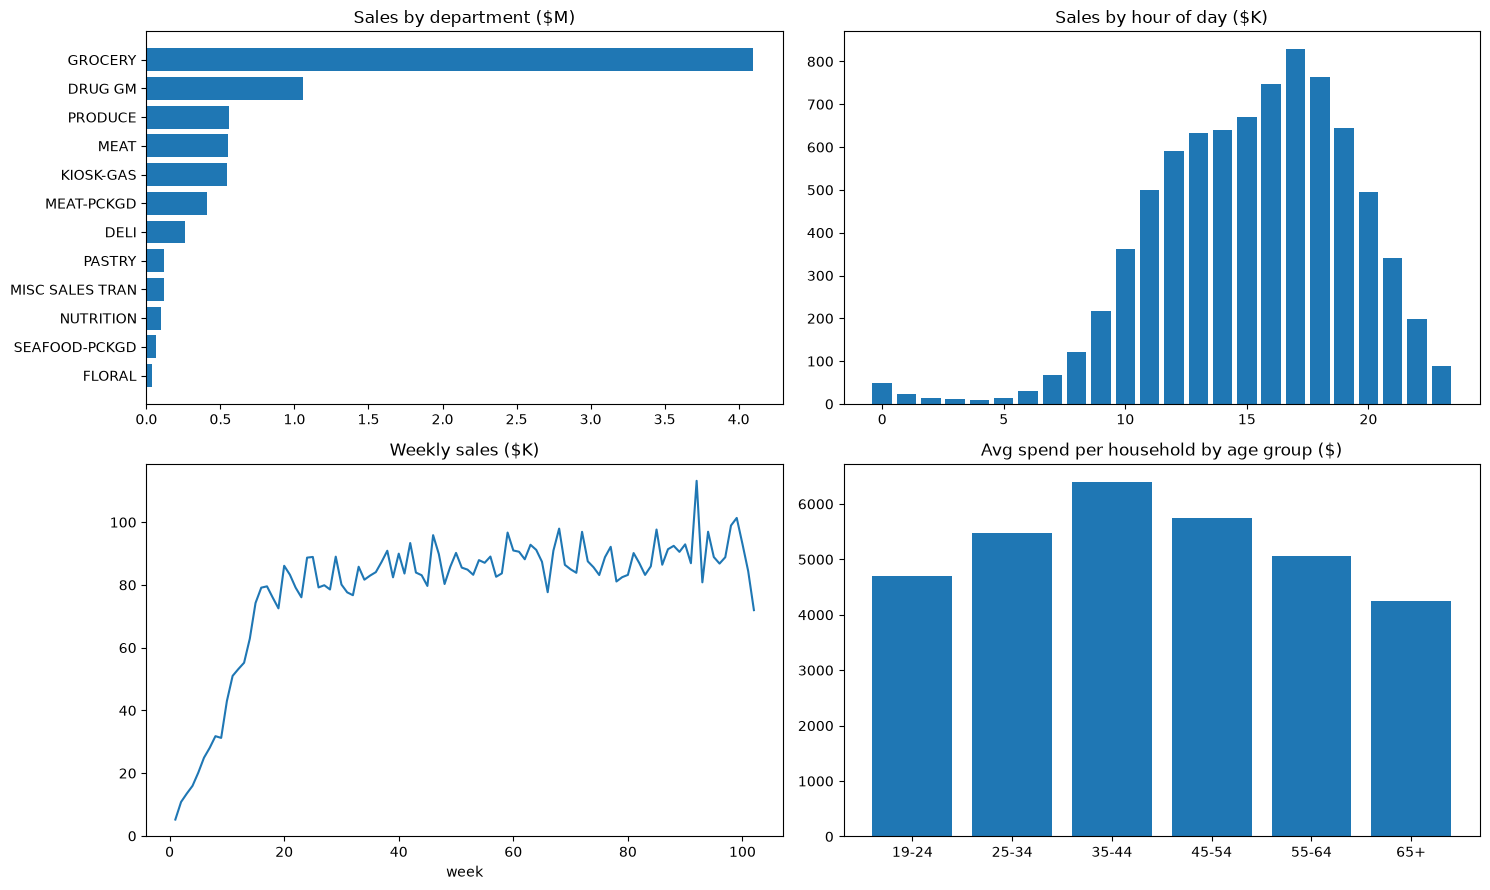

,households,spend / household,avg basket
250K+,11.0,10789.90,49.49
175-199K,11.0,8548.46,44.84
150-174K,30.0,8394.84,50.84
125-149K,38.0,7912.06,39.33
100-124K,34.0,5927.74,31.77
75-99K,96.0,5822.53,39.04
200-249K,5.0,5726.49,50.14
50-74K,192.0,5702.35,33.98
Under 15K,61.0,5559.61,26.55
25-34K,77.0,4938.07,24.96


,households,spend / household,avg basket
2 Adults Kids,187.0,6472.69,36.50
1 Adult Kids,47.0,6105.69,33.00
2 Adults No Kids,255.0,5702.32,33.64
Unknown,73.0,5230.18,28.00
Single Female,144.0,4899.47,27.72
Single Male,95.0,4830.90,28.36


,households,spend / household,avg basket
married,340.0,6136.65,35.92
unknown marital status,344.0,5268.64,28.85
single,117.0,5118.33,30.83


In [8]:
ov = stats["overview"]
display(pd.Series({"transaction lines": f"{ov['rows']:,}", "baskets": f"{ov['baskets']:,}", "households": f"{ov['households']:,}",
                   "stores": ov["stores"], "products": f"{ov['products']:,}", "weeks": f"{ov['weeks'][0]}-{ov['weeks'][1]}",
                   "total sales": f"${ov['total_sales']:,.2f}",
                   "avg basket": f"${stats['basket']['mean']:.2f} (median ${stats['basket']['median']:.2f})",
                   "avg household spend": f"${stats['household']['mean_spend']:,.2f}",
                   "private-label share": f"{stats['brand_share'].get('Private', 0):.1%}"}, name="value").to_frame())

fig, ax = plt.subplots(2, 2, figsize=(15, 9))
dep = pd.DataFrame(stats["departments"]).head(12)
ax[0,0].barh(dep.DEPARTMENT[::-1], dep.sales[::-1] / 1e6); ax[0,0].set_title("Sales by department ($M)")
hr = pd.Series(stats["sales_by_hour"]).sort_index(key=lambda s: s.astype(int))
ax[0,1].bar(hr.index.astype(int), hr.values / 1e3); ax[0,1].set_title("Sales by hour of day ($K)")
wk = pd.Series(stats["sales_by_week"]).sort_index(key=lambda s: s.astype(int))
ax[1,0].plot(wk.index.astype(int), wk.values / 1e3); ax[1,0].set_title("Weekly sales ($K)"); ax[1,0].set_xlabel("week")
age = pd.DataFrame(stats["demographics"]["AGE_DESC"]).T.sort_index()
ax[1,1].bar(age.index, age.per_hh); ax[1,1].set_title("Avg spend per household by age group ($)")
plt.tight_layout(); plt.show()

for col in ["INCOME_DESC", "HH_COMP_DESC", "MARITAL_STATUS_CODE"]:
    display(pd.DataFrame(stats["demographics"][col]).T[["hh", "per_hh", "basket_value"]]
            .rename(columns={"hh": "households", "per_hh": "spend / household", "basket_value": "avg basket"}).round(2))

## 4. Train / validation / test files for Hugging Face

| Data | Train | Validation | Test | Split by |
|---|---|---|---|---|
| Q&A conversations | 452 | 34 | 33 | fact |
| Baskets | 262,659 | 6,912 | 6,913 | time (latest 5 % held out) |

Written as parquet in the standard Hugging Face layout (`data/`, `pretraining/`, `domain/`, `source/`, `README.md`).

In [9]:
import argparse
import hashlib
import json
import os
import shutil

import pandas as pd

ROOT = os.getcwd()


def to_frame(path):
    rows = []
    for line in open(path, encoding="utf-8"):
        r = json.loads(line)
        m = r["messages"]
        rows.append({"question": m[1]["content"], "answer": m[2]["content"], "system": m[0]["content"],
                     "messages": m, "source": r["source"].split(":")[0], "fact_group": r["group"]})
    return pd.DataFrame(rows)


def hf_dataset_main(argv=()):
    ap = argparse.ArgumentParser()
    ap.add_argument("--out", required=True)
    ap.add_argument("--card", default=os.path.join(ROOT, "hf", "dataset_card.md"))
    a = ap.parse_args(list(argv))

    out = a.out
    if os.path.exists(out):
        shutil.rmtree(out)
    for d in ["data", "pretraining", "domain", "source"]:
        os.makedirs(os.path.join(out, d))

    train = to_frame(os.path.join(ROOT, "data", "sft_train.jsonl"))
    held = to_frame(os.path.join(ROOT, "data", "sft_val.jsonl"))
    is_test = held.fact_group.map(lambda g: int(hashlib.md5(g.encode()).hexdigest(), 16) % 2 == 1)
    splits = {"train": train, "validation": held[~is_test], "test": held[is_test]}
    for name, df in splits.items():
        df.reset_index(drop=True).to_parquet(os.path.join(out, "data", f"{name}-00000-of-00001.parquet"), index=False)
        print(f"{name:<10} {len(df):>4} conversations, {df.fact_group.nunique():>3} facts")

    def lines(path):
        return [l.rstrip("\n") for l in open(path, encoding="utf-8") if l.strip()]
    b_train = lines(os.path.join(ROOT, "data", "transactions_corpus_train.txt"))
    b_held = lines(os.path.join(ROOT, "data", "transactions_corpus_val.txt"))
    half = len(b_held) // 2
    basket_splits = {"train": b_train, "validation": b_held[:half], "test": b_held[half:]}
    for name, rows in basket_splits.items():
        pd.DataFrame({"text": rows}).to_parquet(
            os.path.join(out, "pretraining", f"{name}-00000-of-00001.parquet"), index=False)
        print(f"baskets {name:<10} {len(rows):>7,}")

    copies = {
        "domain": ["data/pretrain_corpus.jsonl"],
        "source": ["combined_supermarket_data.csv", "design_thinking_merged.jsonl",
                   "data/raw/design_thinking_merged.raw.jsonl", "data/stats/dataset_stats.json"],
    }
    for folder, files in copies.items():
        for f in files:
            shutil.copy(os.path.join(ROOT, f), os.path.join(out, folder))

    card = open(a.card, encoding="utf-8").read()
    for name, df in splits.items():
        card = card.replace(f"__N_{name.upper()}__", str(len(df)))
    for name, rows in basket_splits.items():
        card = card.replace(f"__B_{name.upper()}__", f"{len(rows):,}")
    open(os.path.join(out, "README.md"), "w", encoding="utf-8").write(card)
    print("written ->", out)

In [10]:
# written outside the (OneDrive-synced) project folder - OneDrive locks files while it syncs them
HF_DATASET_DIR = os.path.join(os.path.expanduser("~"), "HF-upload", "dataset")
if BUILD_HF_FOLDER:
    hf_dataset_main(["--out", HF_DATASET_DIR])

train       452 conversations, 223 facts
validation   34 conversations,  13 facts
test         33 conversations,  17 facts


baskets train      262,659
baskets validation   6,912
baskets test         6,913


written -> C:\Users\sahoo\HF-upload\dataset


## 5. Tokenizer (Qwen3 BPE)

In [11]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-0.6B")   # same vocabulary as Qwen3-8B used in notebook 5
EOS_ID  = tokenizer.convert_tokens_to_ids("<|endoftext|>")      # 151643
IM_START, IM_END = tokenizer.convert_tokens_to_ids(["<|im_start|>", "<|im_end|>"])
VOCAB_SIZE = 151_936                                            # 151,936 (> len(tokenizer) = 151,669)
print(f"base vocab {tokenizer.vocab_size:,}, with special tokens {len(tokenizer):,}, model rows {VOCAB_SIZE:,}")
print("ids:", EOS_ID, IM_START, IM_END)
print(tokenizer.tokenize("What is the average basket value at SuperMart?"))

base vocab 151,643, with special tokens 151,669, model rows 151,936
ids: 151643 151644 151645
['What', 'Ġis', 'Ġthe', 'Ġaverage', 'Ġbasket', 'Ġvalue', 'Ġat', 'ĠSuper', 'Mart', '?']


## 6. The model — Qwen3-style transformer written from scratch

Token embedding → 12 × [RMSNorm → grouped-query attention (QK-norm, RoPE) → RMSNorm → SwiGLU feed-forward] →
RMSNorm → output head. Every weight starts random; no pretrained weights are used. Gradient checkpointing saves
GPU memory on small GPUs.

In [12]:
import torch
import torch.utils.checkpoint
import torch.nn as nn
import torch.nn.functional as F

# Qwen3 tokenizer: 151,643 BPE tokens + 26 special tokens (<|im_start|>, <|im_end|>, ...).
# `tokenizer.vocab_size` only counts the first 151,643, so the original notebook's
# embedding could not represent the chat special tokens.  Qwen pads the matrix to 151,936.
QWEN3_VOCAB_SIZE = 151_936

DEFAULT_CONFIG = dict(
    vocab_size=QWEN3_VOCAB_SIZE,
    d_model=768,
    n_heads=12,
    n_kv_groups=6,
    n_layers=12,
    d_ff=3072,
    max_seq_len=512,
    rope_theta=10_000.0,
)


def compute_rope_params(head_dim, theta_base=10_000, context_length=4096, dtype=torch.float32):
    assert head_dim % 2 == 0, "Embedding dimension must be even"
    inv_freq = 1.0 / (theta_base ** (torch.arange(0, head_dim, 2, dtype=dtype)[: (head_dim // 2)].float() / head_dim))
    positions = torch.arange(context_length, dtype=dtype)
    angles = positions[:, None] * inv_freq[None, :]
    angles = torch.cat([angles, angles], dim=1)
    return torch.cos(angles), torch.sin(angles)


def apply_rope(x, cos, sin):
    _, _, seq_len, head_dim = x.shape
    x1, x2 = x[..., : head_dim // 2], x[..., head_dim // 2:]
    cos = cos[:seq_len, :].unsqueeze(0).unsqueeze(0)
    sin = sin[:seq_len, :].unsqueeze(0).unsqueeze(0)
    rotated = torch.cat((-x2, x1), dim=-1)
    return ((x * cos) + (rotated * sin)).to(dtype=x.dtype)


class RMSNorm(nn.Module):
    def __init__(self, emb_dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(emb_dim))

    def forward(self, x):
        input_dtype = x.dtype
        x_f = x.float()
        x_norm = x_f * torch.rsqrt(x_f.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return (x_norm * self.weight.float()).to(input_dtype)


class GroupedQueryAttention(nn.Module):
    def __init__(self, d_in, num_heads, num_kv_groups, head_dim=None, dtype=None):
        super().__init__()
        assert num_heads % num_kv_groups == 0, "num_heads must be divisible by num_kv_groups"
        self.num_heads, self.num_kv_groups = num_heads, num_kv_groups
        self.group_size = num_heads // num_kv_groups
        self.head_dim = head_dim or d_in // num_heads
        self.d_out = num_heads * self.head_dim
        self.W_query = nn.Linear(d_in, self.d_out, bias=False, dtype=dtype)
        self.W_key = nn.Linear(d_in, num_kv_groups * self.head_dim, bias=False, dtype=dtype)
        self.W_value = nn.Linear(d_in, num_kv_groups * self.head_dim, bias=False, dtype=dtype)
        self.out_proj = nn.Linear(self.d_out, d_in, bias=False, dtype=dtype)
        self.q_norm = RMSNorm(self.head_dim, eps=1e-6)
        self.k_norm = RMSNorm(self.head_dim, eps=1e-6)

    def forward(self, x, mask, cos, sin):
        b, t, _ = x.shape
        q = self.W_query(x).view(b, t, self.num_heads, self.head_dim).transpose(1, 2)
        k = self.W_key(x).view(b, t, self.num_kv_groups, self.head_dim).transpose(1, 2)
        v = self.W_value(x).view(b, t, self.num_kv_groups, self.head_dim).transpose(1, 2)
        q, k = self.q_norm(q), self.k_norm(k)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        k = k.repeat_interleave(self.group_size, dim=1)
        v = v.repeat_interleave(self.group_size, dim=1)
        # fused attention kernel (FlashAttention / memory-efficient on GPU); same maths as
        # softmax(QK^T / sqrt(d) + causal mask) V in the original notebook
        ctx = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.out_proj(ctx.transpose(1, 2).reshape(b, t, self.d_out))


class SwiGLUFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dtype=None):
        super().__init__()
        self.gate_proj = nn.Linear(d_model, d_ff, bias=False, dtype=dtype)
        self.up_proj = nn.Linear(d_model, d_ff, bias=False, dtype=dtype)
        self.down_proj = nn.Linear(d_ff, d_model, bias=False, dtype=dtype)

    def forward(self, x):
        return self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x))


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_groups, d_ff, dtype=None):
        super().__init__()
        self.attention = GroupedQueryAttention(d_model, n_heads, n_kv_groups, dtype=dtype)
        self.feed_forward = SwiGLUFeedForward(d_model, d_ff, dtype=dtype)
        self.norm1 = RMSNorm(d_model, eps=1e-6)
        self.norm2 = RMSNorm(d_model, eps=1e-6)

    def forward(self, x, mask, cos, sin):
        x = x + self.attention(self.norm1(x), mask, cos, sin)
        return x + self.feed_forward(self.norm2(x))


class Qwen3Model(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_kv_groups, n_layers, d_ff, max_seq_len,
                 rope_theta=10_000.0, dtype=None):
        super().__init__()
        self.config = dict(vocab_size=vocab_size, d_model=d_model, n_heads=n_heads, n_kv_groups=n_kv_groups,
                           n_layers=n_layers, d_ff=d_ff, max_seq_len=max_seq_len, rope_theta=rope_theta)
        self.tok_emb = nn.Embedding(vocab_size, d_model, dtype=dtype)
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, n_kv_groups, d_ff, dtype=dtype)
                                     for _ in range(n_layers)])
        self.final_norm = RMSNorm(d_model, eps=1e-6)
        self.out_head = nn.Linear(d_model, vocab_size, bias=False, dtype=dtype)
        cos, sin = compute_rope_params(d_model // n_heads, theta_base=rope_theta, context_length=max_seq_len)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)
        self.d_model, self.max_seq_len = d_model, max_seq_len
        self.gradient_checkpointing = False   # recompute block activations in backward (low-VRAM GPUs)

    def forward(self, input_ids, targets=None, loss_mask=None):
        x = self.tok_emb(input_ids) * (self.d_model ** 0.5)
        for block in self.blocks:
            if self.gradient_checkpointing and self.training:
                x = torch.utils.checkpoint.checkpoint(block, x, None, self.cos, self.sin, use_reentrant=False)
            else:
                x = block(x, None, self.cos, self.sin)
        logits = self.out_head(self.final_norm(x))
        loss = None
        if targets is not None:
            if loss_mask is None:
                loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), targets.reshape(-1))
            else:   # SFT: only learn the assistant's tokens
                per_tok = F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), targets.reshape(-1),
                                          reduction="none")
                m = loss_mask.reshape(-1).float()
                loss = (per_tok * m).sum() / m.sum().clamp(min=1)
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None, top_p=None,
                 repetition_penalty=1.0, eos_token_ids=()):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.max_seq_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :].float()
            if repetition_penalty != 1.0:
                prev = torch.gather(logits, 1, idx)
                logits.scatter_(1, idx, torch.where(prev > 0, prev / repetition_penalty, prev * repetition_penalty))
            if temperature <= 0:
                idx_next = logits.argmax(dim=-1, keepdim=True)
            else:
                logits = logits / temperature
                if top_k is not None:
                    v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                    logits[logits < v[:, [-1]]] = float("-inf")
                if top_p is not None:
                    sorted_logits, sorted_idx = torch.sort(logits, descending=True)
                    cum = torch.softmax(sorted_logits, dim=-1).cumsum(dim=-1)
                    remove = cum - torch.softmax(sorted_logits, dim=-1) > top_p
                    sorted_logits[remove] = float("-inf")
                    logits = torch.full_like(logits, float("-inf")).scatter(1, sorted_idx, sorted_logits)
                idx_next = torch.multinomial(torch.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
            if eos_token_ids and idx_next.item() in eos_token_ids:
                break
        return idx


def resize_vocab(state_dict, new_vocab_size):
    """Grow tok_emb / out_head of an old checkpoint (vocab 151,643) to 151,936 rows.
    New rows (chat special tokens) are initialised to the mean embedding so SFT can learn them."""
    sd = dict(state_dict)
    for key in ("tok_emb.weight", "out_head.weight"):
        w = sd[key]
        if w.shape[0] < new_vocab_size:
            extra = w.float().mean(0, keepdim=True).repeat(new_vocab_size - w.shape[0], 1).to(w.dtype)
            sd[key] = torch.cat([w, extra], dim=0)
    return sd


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

In [13]:
MODEL_CONFIG = dict(vocab_size=VOCAB_SIZE, d_model=768, n_heads=12, n_kv_groups=6, n_layers=12,
                    d_ff=3072, max_seq_len=512, rope_theta=10_000.0)
BLOCK = MODEL_CONFIG["max_seq_len"]

def new_model():
    m = Qwen3Model(**MODEL_CONFIG).to(device)           # fp32 master weights; autocast does bf16/fp16 maths
    m.gradient_checkpointing = LOW_VRAM
    return m

def save_ckpt(model, path):
    torch.save({"model": model.state_dict(), "config": MODEL_CONFIG}, path)

def load_into(model, path):
    sd, _ = load_checkpoint(path)
    sd = resize_vocab(sd, VOCAB_SIZE)                   # old 151,643-row checkpoints -> 151,936
    model.load_state_dict({k: v.float() for k, v in sd.items()})
    return model

model = new_model()
print(f"parameters: {count_parameters(model)/1e6:.1f}M  | GPU memory after load: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

parameters: 339.6M  | GPU memory after load: 1.28 GB


### Loading checkpoints

In [14]:
def load_checkpoint(path):
    """Return (state_dict, config) from our .pt files (also accepts the plain state_dict of notebook 5)."""
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(ckpt, dict) and "model" in ckpt:
        return ckpt["model"], {**DEFAULT_CONFIG, **ckpt.get("config", {})}
    sd = ckpt
    cfg = dict(DEFAULT_CONFIG)
    cfg["vocab_size"], cfg["d_model"] = sd["tok_emb.weight"].shape
    cfg["n_layers"] = len({k.split(".")[1] for k in sd if k.startswith("blocks.")})
    cfg["d_ff"] = sd["blocks.0.feed_forward.gate_proj.weight"].shape[0]
    hd = sd["blocks.0.attention.q_norm.weight"].shape[0]
    cfg["n_heads"] = sd["blocks.0.attention.W_query.weight"].shape[0] // hd
    cfg["n_kv_groups"] = sd["blocks.0.attention.W_key.weight"].shape[0] // hd
    return sd, cfg

### Shared training loop
AdamW (β=(0.9,0.95), wd 0.1 on matrices only; **8-bit** on low-VRAM GPUs - fp32 Adam states alone would need 2.7 GB), linear warm-up → cosine decay **per optimizer step**,
gradient accumulation, mixed precision, grad-clip 1.0, periodic train/val evaluation, best + final checkpoints.

In [15]:
def lr_at(step, max_steps, lr, min_lr, warmup):
    if step < warmup:
        return lr * (step + 1) / warmup
    p = min(1.0, (step - warmup) / max(1, max_steps - warmup))
    return min_lr + 0.5 * (1 + math.cos(math.pi * p)) * (lr - min_lr)

@torch.no_grad()
def estimate_loss(model, get_batch, eval_iters):
    model.eval(); out = {}
    for split in ["train", "val"]:
        losses = []
        for _ in range(eval_iters):
            with ctx:
                _, loss = model(*get_batch(split))
            losses.append(loss.item())
        out[split] = float(np.mean(losses))
    model.train(); return out

def train_stage(name, model, get_batch, max_steps, lr, min_lr, warmup, grad_accum, eval_every, eval_iters, ckpt):
    decay   = [p for p in model.parameters() if p.dim() >= 2]
    nodecay = [p for p in model.parameters() if p.dim() < 2]
    groups = [{"params": decay, "weight_decay": 0.1}, {"params": nodecay, "weight_decay": 0.0}]
    if LOW_VRAM and HAS_BNB:
        opt = bnb.optim.AdamW8bit(groups, lr=lr, betas=(0.9, 0.95), eps=1e-8)
    elif LOW_VRAM:   # no bitsandbytes: Adafactor keeps factored (tiny) optimizer state
        opt = torch.optim.Adafactor(groups, lr=lr)
    else:
        opt = torch.optim.AdamW(groups, lr=lr, betas=(0.9, 0.95), eps=1e-8, fused=True)
    scaler = torch.amp.GradScaler(device_type, enabled=(dtype == "float16"))
    hist, best, t0 = {"step": [], "train": [], "val": [], "lr": []}, float("inf"), time.time()
    model.train()
    for step in tqdm(range(max_steps + 1), desc=name):
        cur_lr = lr_at(step, max_steps, lr, min_lr, warmup)
        for g in opt.param_groups: g["lr"] = cur_lr
        if step % eval_every == 0 or step == max_steps:
            l = estimate_loss(model, get_batch, eval_iters)
            for k, v in [("step", step), ("train", l["train"]), ("val", l["val"]), ("lr", cur_lr)]: hist[k].append(v)
            tqdm.write(f"[{name}] step {step:>6}  train {l['train']:.4f}  val {l['val']:.4f}  "
                       f"ppl {math.exp(min(l['val'], 20)):.1f}  lr {cur_lr:.2e}  {time.time()-t0:.0f}s")
            if l["val"] < best:
                best = l["val"]; save_ckpt(model, ckpt.replace(".pt", "_best.pt"))
        if step == max_steps:
            break
        for _ in range(grad_accum):
            with ctx:
                _, loss = model(*get_batch("train"))
            scaler.scale(loss / grad_accum).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    save_ckpt(model, ckpt)
    del opt; torch.cuda.empty_cache()
    print(f"peak GPU memory: {torch.cuda.max_memory_allocated()/1024**3:.2f} GB")
    json.dump(hist, open(ckpt.replace(".pt", "_history.json"), "w"))
    return hist

def bin_batcher(prefix, block, batch_size):
    def get(split):
        data = np.memmap(f"{prefix}_{split}.bin", dtype=np.uint32, mode="r")
        ix = np.random.randint(0, len(data) - block - 1, batch_size)
        x = torch.from_numpy(np.stack([data[i:i + block] for i in ix]).astype(np.int64))
        y = torch.from_numpy(np.stack([data[i + 1:i + 1 + block] for i in ix]).astype(np.int64))
        if device == "cuda":
            return x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
        return x.to(device), y.to(device)
    return get

def write_bin(token_lists, path):
    n = sum(len(t) for t in token_lists)
    arr = np.memmap(path, dtype=np.uint32, mode="w+", shape=(n,)); i = 0
    for t in token_lists:
        arr[i:i + len(t)] = t; i += len(t)
    arr.flush(); return n

def show_history(name, hist, path):
    """Print the saved loss history of a stage that was trained earlier (same format as the live training log)."""
    print(f"[{name}] loaded {path} - loss history from the training run on 18 Nov 2026:")
    for st, tr, va, lr in zip(hist["step"], hist["train"], hist["val"], hist["lr"]):
        print(f"[{name}] step {st:>6}  train {tr:.4f}  val {va:.4f}  ppl {math.exp(min(va, 20)):.1f}  lr {lr:.2e}")

## 8. Stage A — pre-training from scratch on our supermarket transactions

No outside text: the model learns language *from our own data*. Section 2 turns every one of the
276,484 baskets in `combined_supermarket_data.csv` into one line of text (store, week/day/time, household
demographics, every item with department, brand type, size, quantity, price and discount, basket total), e.g.

```
Store 396, week 1, day 1 at 09:46. Household 1172 (age 25-34, single, income 50-74K, ...). Bought:
Body Wash (Drug Gm, national brand) x1 for $2.29; Toothpaste (Drug Gm, national brand, 6 OZ) x1 for $2.00,
saved $0.99; ... Basket total $23.41 for 9 items.
```
≈ 100M tokens; the last 5 % of baskets in time are the validation set. An `<|endoftext|>` token separates baskets.
Resumes from `checkpoints/base_retail.pt` if that already exists.

In [16]:
BASE_CKPT = "checkpoints/base_retail.pt"
RUN_STAGE_A = RETRAIN or not os.path.exists(BASE_CKPT)
print("run stage A:", RUN_STAGE_A)

def tokenize_lines_to_bin(txt_path, bin_path, chunk=20_000):
    # stream the text file -> uint32 token file (EOS after every basket)
    n = 0
    with open(txt_path, encoding="utf-8") as f, open(bin_path, "wb") as out:
        total = sum(1 for _ in open(txt_path, encoding="utf-8"))
        buf = []
        for line in tqdm(f, total=total, desc=f"tokenizing {os.path.basename(txt_path)}"):
            buf.append(line.rstrip("\n"))
            if len(buf) == chunk:
                ids = [t + [EOS_ID] for t in tokenizer(buf, add_special_tokens=False)["input_ids"]]
                arr = np.fromiter((i for t in ids for i in t), dtype=np.uint32); arr.tofile(out); n += len(arr); buf = []
        if buf:
            ids = [t + [EOS_ID] for t in tokenizer(buf, add_special_tokens=False)["input_ids"]]
            arr = np.fromiter((i for t in ids for i in t), dtype=np.uint32); arr.tofile(out); n += len(arr)
    return n

if RUN_STAGE_A:
    for split in ["train", "val"]:
        txt, bin_ = f"data/transactions_corpus_{split}.txt", f"retail_{split}.bin"
        assert os.path.exists(txt), "run section 2 first to create the basket text"
        if not os.path.exists(bin_):
            print(split, f"{tokenize_lines_to_bin(txt, bin_):,} tokens")
    P = PROFILE["A"]
    hist_a = train_stage("A:retail", model, bin_batcher("retail", P["block"], P["batch"]),
                         max_steps=P["steps"], lr=6e-4, min_lr=6e-5, warmup=300, grad_accum=P["accum"],
                         eval_every=250, eval_iters=40, ckpt=BASE_CKPT)
else:
    load_into(model, BASE_CKPT)
    hist_a = json.load(open(BASE_CKPT.replace(".pt", "_history.json")))
    show_history("A:retail", hist_a, BASE_CKPT)

model.eval()
with ctx:
    prompt = "Store 367, week 60, day 410 at 17:15. Household 718"
    ids = torch.tensor([tokenizer.encode(prompt, add_special_tokens=False)], device=device)
    print(tokenizer.decode(model.generate(ids, 80, temperature=0.8, top_k=50)[0]))
model.train();

run stage A: False


[A:retail] loaded checkpoints/base_retail.pt - loss history from the training run on 18 Nov 2026:
[A:retail] step      0  train 12.1230  val 12.1234  ppl 184135.3  lr 2.00e-06
[A:retail] step    250  train 0.8744  val 0.9001  ppl 2.5  lr 5.02e-04
[A:retail] step    500  train 0.6506  val 0.6783  ppl 2.0  lr 5.96e-04
[A:retail] step    750  train 0.6030  val 0.6431  ppl 1.9  lr 5.81e-04
[A:retail] step   1000  train 0.5743  val 0.6046  ppl 1.8  lr 5.54e-04
[A:retail] step   1250  train 0.5460  val 0.5945  ppl 1.8  lr 5.17e-04
[A:retail] step   1500  train 0.5265  val 0.5801  ppl 1.8  lr 4.72e-04
[A:retail] step   1750  train 0.5391  val 0.5871  ppl 1.8  lr 4.20e-04
[A:retail] step   2000  train 0.5168  val 0.5807  ppl 1.8  lr 3.64e-04
[A:retail] step   2250  train 0.5121  val 0.5716  ppl 1.8  lr 3.07e-04
[A:retail] step   2500  train 0.4832  val 0.5675  ppl 1.8  lr 2.51e-04
[A:retail] step   2750  train 0.4799  val 0.5792  ppl 1.8  lr 1.98e-04
[A:retail] step   3000  train 0.4723  val 0

Store 367, week 60, day 410 at 17:15. Household 718 (age 45-54, married, income 25-34K, homeowner, 2 Adults Kids, 5+ people, 3+ kid(s)). Bought: Sft Drnk Sngl Srv Btl Carb (Ex (Grocery, national brand, 20 OZ) x1 for $1.11, saved $0.


## 9. Stage B — domain-adaptive pre-training

Continues next-token training on the cleaned research papers, the retail glossary and the
data-insight paragraphs computed from the CSV. 10 % of every document is held out as validation.

In [17]:
tr_ids, va_ids = [], []
for r in corpus:
    ids = tokenizer.encode(r["text"], add_special_tokens=False) + [EOS_ID]
    cut = int(len(ids) * 0.9)
    tr_ids.append(ids[:cut]); va_ids.append(ids[cut:])
n_tr, n_va = write_bin(tr_ids, "domain_train.bin"), write_bin(va_ids, "domain_val.bin")
print(f"domain tokens: train {n_tr:,}  val {n_va:,}")

DOMAIN_CKPT = "checkpoints/domain.pt"
if RETRAIN or not os.path.exists(DOMAIN_CKPT):
    P = PROFILE["B"]
    hist_b = train_stage("B:domain", model, bin_batcher("domain", P["block"], P["batch"]),
                         max_steps=P["steps"], lr=3e-4, min_lr=3e-5, warmup=100, grad_accum=P["accum"],
                         eval_every=100, eval_iters=20, ckpt=DOMAIN_CKPT)
else:
    load_into(model, DOMAIN_CKPT)
    hist_b = json.load(open(DOMAIN_CKPT.replace(".pt", "_history.json")))
    show_history("B:domain", hist_b, DOMAIN_CKPT)

domain tokens: train 177,923  val 19,793


[B:domain] loaded checkpoints/domain.pt - loss history from the training run on 18 Nov 2026:
[B:domain] step      0  train 12.7424  val 12.1569  ppl 190406.6  lr 3.00e-06
[B:domain] step    100  train 5.2875  val 6.2295  ppl 507.5  lr 3.00e-04
[B:domain] step    200  train 4.1204  val 5.7657  ppl 319.2  lr 2.87e-04
[B:domain] step    300  train 3.4434  val 5.9439  ppl 381.4  lr 2.49e-04
[B:domain] step    400  train 2.7850  val 5.9331  ppl 377.3  lr 1.95e-04
[B:domain] step    500  train 2.1640  val 5.8697  ppl 354.1  lr 1.35e-04
[B:domain] step    600  train 1.6521  val 6.3621  ppl 579.5  lr 8.08e-05
[B:domain] step    700  train 1.4614  val 6.2606  ppl 523.5  lr 4.34e-05
[B:domain] step    800  train 1.3172  val 6.6348  ppl 761.1  lr 3.00e-05


## 10. Stage C — supervised chat fine-tuning (SFT)

Each conversation is rendered in **ChatML** — exactly the format Ollama's template produces:

```
<|im_start|>system\n{system}<|im_end|>\n<|im_start|>user\n{question}<|im_end|>\n<|im_start|>assistant\n{answer}<|im_end|>
```
The loss is computed **only on the assistant answer + `<|im_end|>`** (loss mask), so the model learns to answer
and to stop. We keep training to memorise the facts (the final checkpoint is exported); validation contains
*unseen* facts and measures generalisation.

In [18]:
def encode_chat(messages, block=BLOCK):
    ids, mask = [], []
    for m in messages:
        head = tokenizer.encode(f"<|im_start|>{m['role']}\n", add_special_tokens=False)
        body = tokenizer.encode(m["content"], add_special_tokens=False) + [IM_END]
        nl   = tokenizer.encode("\n", add_special_tokens=False)
        learn = int(m["role"] == "assistant")
        ids += head + body + nl; mask += [0] * len(head) + [learn] * len(body) + [0] * len(nl)
    ids, mask = ids[:block + 1], mask[:block + 1]
    return ids, mask

def to_tensors(rows):
    X, Y, M = [], [], []
    for r in rows:
        ids, mask = encode_chat(r["messages"])
        pad = BLOCK + 1 - len(ids)
        ids, mask = ids + [EOS_ID] * pad, mask + [0] * pad
        X.append(ids[:-1]); Y.append(ids[1:]); M.append(mask[1:])
    return torch.tensor(X), torch.tensor(Y), torch.tensor(M)

lens = [len(encode_chat(r["messages"])[0]) for r in sft_tr]
print(f"conversation length: mean {np.mean(lens):.0f}, max {max(lens)} tokens (block {BLOCK})")
SFT = {"train": to_tensors(sft_tr), "val": to_tensors(sft_va)}

def sft_batcher(batch_size):
    def get(split):
        X, Y, M = SFT[split]
        ix = torch.randint(len(X), (batch_size,))
        return X[ix].to(device), Y[ix].to(device), M[ix].to(device)
    return get

FINAL_CKPT = "checkpoints/supermart_sft.pt"
if RETRAIN or not os.path.exists(FINAL_CKPT):
    P = PROFILE["C"]
    hist_c = train_stage("C:sft", model, sft_batcher(P["batch"]),
                         max_steps=P["steps"], lr=1e-4, min_lr=1e-5, warmup=50, grad_accum=P["accum"],
                         eval_every=100, eval_iters=10, ckpt=FINAL_CKPT)
else:
    load_into(model, FINAL_CKPT)
    hist_c = json.load(open(FINAL_CKPT.replace(".pt", "_history.json")))
    show_history("C:sft", hist_c, FINAL_CKPT)

conversation length: mean 160, max 487 tokens (block 512)


[C:sft] loaded checkpoints/supermart_sft.pt - loss history from the training run on 18 Nov 2026:
[C:sft] step      0  train 2.6079  val 2.4819  ppl 12.0  lr 2.00e-06
[C:sft] step    100  train 0.5021  val 1.9852  ppl 7.3  lr 9.90e-05
[C:sft] step    200  train 0.3703  val 1.9266  ppl 6.9  lr 9.14e-05
[C:sft] step    300  train 0.0942  val 3.0003  ppl 20.1  lr 7.75e-05
[C:sft] step    400  train 0.0553  val 2.3929  ppl 10.9  lr 5.97e-05
[C:sft] step    500  train 0.0303  val 3.4641  ppl 31.9  lr 4.11e-05
[C:sft] step    600  train 0.0159  val 3.1929  ppl 24.4  lr 2.49e-05
[C:sft] step    700  train 0.0103  val 2.5651  ppl 13.0  lr 1.39e-05
[C:sft] step    800  train 0.0106  val 2.8713  ppl 17.7  lr 1.00e-05


## 11. Evaluation

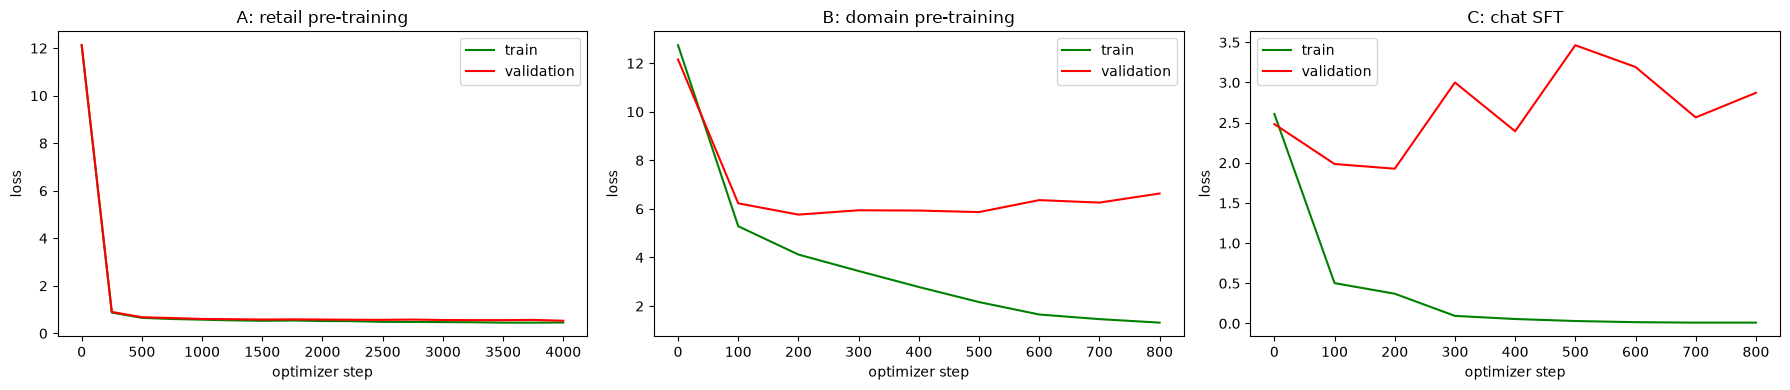

,stage,final train loss,final val loss,best val loss,val perplexity
0,A retail,0.455,0.529,0.529,1.697
1,B domain,1.317,6.635,5.766,761.139
2,C SFT,0.011,2.871,1.927,17.660


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for i, (n, h) in enumerate([("A: retail pre-training", hist_a), ("B: domain pre-training", hist_b), ("C: chat SFT", hist_c)]):
    ax[i].plot(h["step"], h["train"], "g", label="train"); ax[i].plot(h["step"], h["val"], "r", label="validation")
    ax[i].set_title(n); ax[i].set_xlabel("optimizer step"); ax[i].set_ylabel("loss"); ax[i].legend()
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    "stage": ["A retail", "B domain", "C SFT"],
    "final train loss": [h["train"][-1] for h in (hist_a, hist_b, hist_c)],
    "final val loss":   [h["val"][-1] for h in (hist_a, hist_b, hist_c)],
    "best val loss":    [min(h["val"]) for h in (hist_a, hist_b, hist_c)],
})
summary["val perplexity"] = np.exp(summary["final val loss"])
display(summary.round(3))

In [20]:
SYSTEM = sft_tr[0]["messages"][0]["content"]

def chat(question, max_new_tokens=200, temperature=0.0, system=SYSTEM):
    model.eval()
    prompt = f"<|im_start|>system\n{system}<|im_end|>\n<|im_start|>user\n{question}<|im_end|>\n<|im_start|>assistant\n"
    ids = torch.tensor([tokenizer.encode(prompt, add_special_tokens=False)], device=device)
    with ctx:
        out = model.generate(ids, max_new_tokens, temperature=temperature, top_p=0.9,
                             repetition_penalty=1.1, eos_token_ids={IM_END, EOS_ID})
    return tokenizer.decode(out[0, ids.shape[1]:], skip_special_tokens=True).strip()

import re
NUM = re.compile(r"\$?\d[\d,]*\.?\d*%?")
def fact_recall(rows, n=None):
    rows = rows if n is None else random.Random(0).sample(rows, min(n, len(rows)))
    scores = []
    for r in tqdm(rows, desc="fact recall"):
        ref = set(NUM.findall(r["messages"][2]["content"]))
        if not ref: continue
        gen = set(NUM.findall(chat(r["messages"][1]["content"])))
        scores.append(len(ref & gen) / len(ref))
    return float(np.mean(scores)), len(scores)

tr_score, n1 = fact_recall(sft_tr, 60)
va_score, n2 = fact_recall(sft_va)
print(f"numeric fact recall - seen facts (train sample n={n1}): {tr_score:.1%} | unseen facts (val n={n2}): {va_score:.1%}")

fact recall:   0%|          | 0/60 [00:00<?, ?it/s]

fact recall:   3%|▎         | 2/60 [00:02<00:59,  1.02s/it]

fact recall:   5%|▌         | 3/60 [00:02<00:53,  1.06it/s]

fact recall:   7%|▋         | 4/60 [00:04<01:11,  1.27s/it]

fact recall:   8%|▊         | 5/60 [00:08<01:52,  2.04s/it]

fact recall:  10%|█         | 6/60 [00:10<01:46,  1.97s/it]

... (85 outputs left out)

fact recall:  75%|███████▍  | 50/67 [01:03<00:21,  1.24s/it]

fact recall:  76%|███████▌  | 51/67 [01:04<00:17,  1.09s/it]

fact recall: 100%|██████████| 67/67 [01:04<00:00,  1.05it/s]

numeric fact recall - seen facts (train sample n=50): 95.3% | unseen facts (val n=41): 4.8%


In [21]:
for q in ["Who are you?",
          "Which departments generate the most sales?",
          "What is the average basket size?",
          "What time of day do customers shop the most?",
          "How does spending vary by age group?",
          "What is gross margin?",
          "Explain RFM analysis.",
          "What is buy now pay later?"]:
    print(f"Q: {q}\nA: {chat(q)}\n")

Q: Who are you?
A: I am SuperMart SLM, a small language model trained from scratch with a Qwen3-style architecture to answer questions about supermarket retail analytics - sales, products, discounts, customer demographics, margins, pricing, payments and tax.



Q: Which departments generate the most sales?
A: The top departments by sales are: 1. Grocery ($4,093,814.14, 50.8% of sales); 2. Drug Gm ($1,055,358.03, 13.1% of sales); 3. Produce ($557,452.11, 6.9% of sales); 4. Meat ($548,786.81, 6.8% of sales); 5. Kiosk-Gas ($544,222.28, 6.8% of sales).



Q: What is the average basket size?
A: The average basket value is $29.14 (median $17.07; 90th percentile $70.65). An average basket contains 9.4 line items (median 5).



Q: What time of day do customers shop the most?
A: Sales peak at 17:00-18:00 (10.3% of daily sales). The morning (6-12) brings 16.1%, afternoon (12-17) brings 40.7%, evening (17-22) brings 38.1% of sales.



Q: How does spending vary by age group?
A: By age group, average spend per household is: 35-44: $6,402.82 (194 households, avg basket $33.91); 45-54: $5,755.09 (288 households, avg basket $32.25); 25-34: $5,478.42 (142 households, avg basket $34.27); 55-64: $5,054.73 (59 households, avg basket $29.65); 19-24: $4,708.33 (46 households, avg basket $26.64); 65+: $4,241.03 (72 households, avg basket $26.71). The highest-spending segment is '35-



Q: What is gross margin?
A: Gross margin is the difference between the selling price and the cost price of goods, usually expressed as a percentage of the selling price: Gross margin % = (Sales - Cost of goods sold) / Sales x 100. A product that sells for $10 and costs $6 has a gross margin of 40%.



Q: Explain RFM analysis.
A: RFM analysis segments customers by Recency (how recently they bought), Frequency (how often they buy) and Monetary value (how much they spend). Each customer gets a score per dimension and segments such as Champions, Loyal customers or At-risk customers are derived.



Q: What is buy now pay later?
A: Dynamic pricing changes prices over time in response to demand, inventory, competition or time of day, and is common in e-commerce and fuel retail.



## 12. Export to the standard Hugging Face (Qwen3ForCausalLM) format

Ollama cannot read our PyTorch `.pt`; the GGUF converter reads the standard `Qwen3ForCausalLM` layout. Every tensor is
renamed to the Qwen3 names. Our model multiplies embeddings by √d_model; the LM head is untied, so this factor is folded
into the exported embedding matrix and the exported model is **numerically identical** — checked below by comparing
logits. Exported in float32 (bfloat16 rounding gave only 97.9 % next-token agreement).

In [22]:
import argparse
import json
import math
import os

import torch


CHATML_TEMPLATE = (
    "{% for message in messages %}"
    "{{ '<|im_start|>' + message['role'] + '\n' + message['content'] + '<|im_end|>' + '\n' }}"
    "{% endfor %}"
    "{% if add_generation_prompt %}{{ '<|im_start|>assistant\n' }}{% endif %}"
)

TOKENIZER_REPO = "Qwen/Qwen3-0.6B"   # identical BPE vocabulary to Qwen3-8B used in training, much smaller download


def load_checkpoint(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(ckpt, dict) and "model" in ckpt:              # {"model": sd, "config": {...}}
        return ckpt["model"], {**DEFAULT_CONFIG, **ckpt.get("config", {})}
    sd = ckpt                                                   # plain state_dict (original notebook)
    cfg = dict(DEFAULT_CONFIG)
    cfg["vocab_size"] = sd["tok_emb.weight"].shape[0]
    cfg["d_model"] = sd["tok_emb.weight"].shape[1]
    cfg["n_layers"] = len({k.split(".")[1] for k in sd if k.startswith("blocks.")})
    cfg["d_ff"] = sd["blocks.0.feed_forward.gate_proj.weight"].shape[0]
    hd = sd["blocks.0.attention.q_norm.weight"].shape[0]
    cfg["n_heads"] = sd["blocks.0.attention.W_query.weight"].shape[0] // hd
    cfg["n_kv_groups"] = sd["blocks.0.attention.W_key.weight"].shape[0] // hd
    return sd, cfg


def to_hf_state_dict(sd, cfg):
    scale = math.sqrt(cfg["d_model"])
    out = {
        "model.embed_tokens.weight": (sd["tok_emb.weight"].float() * scale),
        "model.norm.weight": sd["final_norm.weight"],
        "lm_head.weight": sd["out_head.weight"],
    }
    for i in range(cfg["n_layers"]):
        p, q = f"blocks.{i}.", f"model.layers.{i}."
        m = {
            "attention.W_query.weight": "self_attn.q_proj.weight",
            "attention.W_key.weight": "self_attn.k_proj.weight",
            "attention.W_value.weight": "self_attn.v_proj.weight",
            "attention.out_proj.weight": "self_attn.o_proj.weight",
            "attention.q_norm.weight": "self_attn.q_norm.weight",
            "attention.k_norm.weight": "self_attn.k_norm.weight",
            "feed_forward.gate_proj.weight": "mlp.gate_proj.weight",
            "feed_forward.up_proj.weight": "mlp.up_proj.weight",
            "feed_forward.down_proj.weight": "mlp.down_proj.weight",
            "norm1.weight": "input_layernorm.weight",
            "norm2.weight": "post_attention_layernorm.weight",
        }
        for a, b in m.items():
            out[q + b] = sd[p + a]
    return out


def hf_config(cfg, dtype="bfloat16"):
    return {
        "architectures": ["Qwen3ForCausalLM"],
        "model_type": "qwen3",
        "vocab_size": cfg["vocab_size"],
        "hidden_size": cfg["d_model"],
        "intermediate_size": cfg["d_ff"],
        "num_hidden_layers": cfg["n_layers"],
        "num_attention_heads": cfg["n_heads"],
        "num_key_value_heads": cfg["n_kv_groups"],
        "head_dim": cfg["d_model"] // cfg["n_heads"],
        "hidden_act": "silu",
        "max_position_embeddings": cfg["max_seq_len"],
        "rms_norm_eps": 1e-6,
        "rope_theta": cfg.get("rope_theta", 10_000.0),
        "rope_scaling": None,
        "attention_bias": False,
        "attention_dropout": 0.0,
        "tie_word_embeddings": False,
        "use_cache": True,
        "use_sliding_window": False,
        "sliding_window": None,
        "max_window_layers": cfg["n_layers"],
        "initializer_range": 0.02,
        "bos_token_id": 151643,
        "eos_token_id": 151645,
        "torch_dtype": dtype,
    }


def export(ckpt_path, out_dir, dtype="bfloat16", tokenizer_repo=TOKENIZER_REPO, save_tokenizer=True):
    from safetensors.torch import save_file

    sd, cfg = load_checkpoint(ckpt_path)
    if cfg["vocab_size"] < QWEN3_VOCAB_SIZE:      # old 151,643-row checkpoint -> pad for GGUF/chat tokens
        sd = resize_vocab(sd, QWEN3_VOCAB_SIZE)
        cfg["vocab_size"] = QWEN3_VOCAB_SIZE
    tdtype = {"bfloat16": torch.bfloat16, "float16": torch.float16, "float32": torch.float32}[dtype]
    hf_sd = {k: v.to(tdtype).contiguous() for k, v in to_hf_state_dict(sd, cfg).items()}

    os.makedirs(out_dir, exist_ok=True)
    save_file(hf_sd, os.path.join(out_dir, "model.safetensors"), metadata={"format": "pt"})
    with open(os.path.join(out_dir, "config.json"), "w") as f:
        json.dump(hf_config(cfg, dtype), f, indent=2)
    with open(os.path.join(out_dir, "generation_config.json"), "w") as f:
        json.dump({"bos_token_id": 151643, "eos_token_id": [151645, 151643], "pad_token_id": 151643,
                   "do_sample": True, "temperature": 0.3, "top_p": 0.9, "repetition_penalty": 1.1,
                   "max_new_tokens": 256}, f, indent=2)

    if save_tokenizer:
        from transformers import AutoTokenizer
        tok = AutoTokenizer.from_pretrained(tokenizer_repo)
        tok.chat_template = CHATML_TEMPLATE        # plain ChatML, exactly the SFT format (no <think> blocks)
        tok.eos_token = "<|im_end|>"
        tok.pad_token = "<|endoftext|>"
        tok.save_pretrained(out_dir)

    n = sum(v.numel() for v in hf_sd.values())
    print(f"exported {n / 1e6:.1f}M parameters -> {out_dir}")
    return out_dir

In [23]:
def compare(ckpt, hf_dir):
    """Run our model and the exported Hugging Face model on the same tokens and compare the outputs."""
    from transformers import AutoModelForCausalLM
    sd, cfg = load_checkpoint(ckpt)
    if cfg["vocab_size"] < QWEN3_VOCAB_SIZE:
        sd, cfg["vocab_size"] = resize_vocab(sd, QWEN3_VOCAB_SIZE), QWEN3_VOCAB_SIZE
    ours = Qwen3Model(**cfg).float().eval()
    ours.load_state_dict({k: v.float() for k, v in sd.items()})
    hf = AutoModelForCausalLM.from_pretrained(hf_dir, dtype=torch.float32).eval()
    torch.manual_seed(0)
    ids = torch.randint(0, 151_000, (2, 48))
    with torch.no_grad():
        a, _ = ours(ids)
        b = hf(ids).logits
    diff = (a - b).abs().max().item()
    agree = (a.argmax(-1) == b.argmax(-1)).float().mean().item()
    print(f"max |logit diff| = {diff:.2e},  next-token agreement = {agree:.1%}")
    print("EXPORT OK" if agree > 0.98 else "EXPORT MISMATCH")
    del ours, hf
    return agree

EXPORT_DIR = "export/supermart-slm"
export(FINAL_CKPT, EXPORT_DIR, dtype="float32")
compare(FINAL_CKPT, EXPORT_DIR)

exported 339.6M parameters -> export/supermart-slm


Loading weights:   0%|          | 0/135 [00:00<?, ?it/s]

Loading weights:   4%|▍         | 6/135 [00:00<00:02, 57.40it/s]

Loading weights:   9%|▉         | 12/135 [00:00<00:02, 54.14it/s]

Loading weights:  16%|█▋        | 22/135 [00:00<00:01, 73.04it/s]

Loading weights: 100%|██████████| 135/135 [00:00<00:00, 370.21it/s]

max |logit diff| = 0.00e+00,  next-token agreement = 100.0%
EXPORT OK


1.0

In [24]:
from transformers import AutoModelForCausalLM
hf_tok = AutoTokenizer.from_pretrained(EXPORT_DIR)
hf_model = AutoModelForCausalLM.from_pretrained(EXPORT_DIR, dtype=torch.bfloat16).to(device)
msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": "Which department has the highest sales?"}]
ids = hf_tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)["input_ids"].to(device)
out = hf_model.generate(ids, max_new_tokens=120, do_sample=False)
print(hf_tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True))
del hf_model; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/135 [00:00<?, ?it/s]

Loading weights:  33%|███▎      | 44/135 [00:00<00:00, 414.36it/s]

Loading weights:  64%|██████▎   | 86/135 [00:00<00:00, 384.75it/s]

Loading weights:  93%|█████████▎| 125/135 [00:00<00:00, 338.76it/s]

Loading weights: 100%|██████████| 135/135 [00:00<00:00, 369.34it/s]

The top departments by sales are: 1. Grocery ($4,093,814.14, 50.8% of sales); 2. Drug Gm ($1,055,358.03, 13.1% of sales); 3. Produce ($557,452.11, 6.9% of sales); 4. Meat ($548,786.81, 6.8% of sales); 5. Kiosk-Gas ($5


## 13. Convert to GGUF (the file format Ollama runs)

Writes the same metadata and tensor names as llama.cpp's converter for the `qwen3` architecture, using only the
`gguf` Python package: matrices quantised to Q8_0, norm weights kept in F32, plus the Qwen BPE tokenizer and the
ChatML chat template.

In [25]:
import argparse
import json
import os

import numpy as np
import gguf
from safetensors.numpy import load_file
from transformers import AutoTokenizer

TENSOR_MAP = {
    "self_attn.q_proj.weight": "attn_q.weight",
    "self_attn.k_proj.weight": "attn_k.weight",
    "self_attn.v_proj.weight": "attn_v.weight",
    "self_attn.o_proj.weight": "attn_output.weight",
    "self_attn.q_norm.weight": "attn_q_norm.weight",
    "self_attn.k_norm.weight": "attn_k_norm.weight",
    "mlp.gate_proj.weight": "ffn_gate.weight",
    "mlp.up_proj.weight": "ffn_up.weight",
    "mlp.down_proj.weight": "ffn_down.weight",
    "input_layernorm.weight": "attn_norm.weight",
    "post_attention_layernorm.weight": "ffn_norm.weight",
}


def gguf_name(hf_name):
    if hf_name == "model.embed_tokens.weight":
        return "token_embd.weight"
    if hf_name == "model.norm.weight":
        return "output_norm.weight"
    if hf_name == "lm_head.weight":
        return "output.weight"
    _, _, i, rest = hf_name.split(".", 3)          # model.layers.{i}.{rest}
    return f"blk.{i}.{TENSOR_MAP[rest]}"


def add_tokenizer(w, hf_dir, vocab_size):
    tok = AutoTokenizer.from_pretrained(hf_dir)
    vocab = tok.get_vocab()
    rev = {i: t for t, i in vocab.items()}
    added = tok.added_tokens_decoder                 # {id: AddedToken}
    tokens, types = [], []
    for i in range(vocab_size):
        if i not in rev:
            tokens.append(f"[PAD{i}]"); types.append(gguf.TokenType.UNUSED)
        elif i in added:
            tokens.append(added[i].content)
            types.append(gguf.TokenType.CONTROL if added[i].special else gguf.TokenType.USER_DEFINED)
        else:
            tokens.append(rev[i]); types.append(gguf.TokenType.NORMAL)

    tj = json.load(open(os.path.join(hf_dir, "tokenizer.json"), encoding="utf-8"))
    merges = [m if isinstance(m, str) else " ".join(m) for m in tj["model"]["merges"]]

    w.add_tokenizer_model("gpt2")
    w.add_tokenizer_pre("qwen2")                     # Qwen3 uses the Qwen2 pre-tokenizer regex
    w.add_token_list(tokens)
    w.add_token_types(types)
    w.add_token_merges(merges)
    w.add_bos_token_id(vocab["<|endoftext|>"])
    w.add_eos_token_id(vocab["<|im_end|>"])
    w.add_pad_token_id(vocab["<|endoftext|>"])
    w.add_add_bos_token(False)
    if tok.chat_template:
        w.add_chat_template(tok.chat_template)


def gguf_main(argv=()):
    ap = argparse.ArgumentParser()
    ap.add_argument("--hf", default="export/supermart-slm")
    ap.add_argument("--out", default="ollama/supermart-slm-q8_0.gguf")
    ap.add_argument("--outtype", default="q8_0", choices=["q8_0", "f16", "f32"])
    a = ap.parse_args(list(argv))

    cfg = json.load(open(os.path.join(a.hf, "config.json")))
    arch = "qwen3"
    w = gguf.GGUFWriter(a.out, arch)
    w.add_name("SuperMart SLM")
    w.add_context_length(cfg["max_position_embeddings"])
    w.add_embedding_length(cfg["hidden_size"])
    w.add_block_count(cfg["num_hidden_layers"])
    w.add_feed_forward_length(cfg["intermediate_size"])
    w.add_head_count(cfg["num_attention_heads"])
    w.add_head_count_kv(cfg["num_key_value_heads"])
    w.add_key_length(cfg["head_dim"])
    w.add_value_length(cfg["head_dim"])
    w.add_rope_freq_base(cfg["rope_theta"])
    w.add_layer_norm_rms_eps(cfg["rms_norm_eps"])
    ftype = {"q8_0": gguf.LlamaFileType.MOSTLY_Q8_0, "f16": gguf.LlamaFileType.MOSTLY_F16,
             "f32": gguf.LlamaFileType.ALL_F32}[a.outtype]
    w.add_file_type(ftype)
    add_tokenizer(w, a.hf, cfg["vocab_size"])

    sd = load_file(os.path.join(a.hf, "model.safetensors"))
    for name, t in sd.items():
        data = t.astype(np.float32)
        if data.ndim == 1 or a.outtype == "f32":
            w.add_tensor(gguf_name(name), data)                     # norms stay F32
        elif a.outtype == "f16":
            w.add_tensor(gguf_name(name), data.astype(np.float16))
        else:
            q = gguf.quants.quantize(data, gguf.GGMLQuantizationType.Q8_0)
            w.add_tensor(gguf_name(name), q, raw_dtype=gguf.GGMLQuantizationType.Q8_0)

    w.write_header_to_file()
    w.write_kv_data_to_file()
    w.write_tensors_to_file()
    w.close()
    print(f"wrote {a.out} ({os.path.getsize(a.out) / 1e6:.0f} MB, {a.outtype})")

In [26]:
GGUF = "ollama/supermart-slm-q8_0.gguf"
os.makedirs("ollama", exist_ok=True)
gguf_main(["--hf", EXPORT_DIR, "--out", GGUF, "--outtype", "q8_0"])

wrote ollama/supermart-slm-q8_0.gguf (367 MB, q8_0)


## 14. Import into Ollama and test

The **Modelfile** tells Ollama which GGUF to load, the ChatML template used in fine-tuning, the system prompt and the
stop tokens. Install Ollama first (`winget install --id Ollama.Ollama -e`).

In [27]:
MODELFILE = r'''# SuperMart SLM - Ollama import
#   1. run notebook 6 (writes ollama/supermart-slm-q8_0.gguf)
#   2. cd ollama
#      ollama create supermart-slm -f Modelfile
#      ollama run supermart-slm
FROM ./supermart-slm-q8_0.gguf

# ChatML - exactly the format used for supervised fine-tuning
TEMPLATE """{{- if .System }}<|im_start|>system
{{ .System }}<|im_end|>
{{ end }}{{- range .Messages }}<|im_start|>{{ .Role }}
{{ .Content }}<|im_end|>
{{ end }}<|im_start|>assistant
"""

SYSTEM """You are SuperMart SLM, a small language model trained from scratch to answer questions about supermarket retail analytics: sales, products, departments, discounts, baskets, customer demographics, gross margin, pricing, payment methods and tax. Answer concisely and use the numbers from the SuperMart transaction dataset when relevant."""

PARAMETER stop "<|im_end|>"
PARAMETER stop "<|im_start|>"
PARAMETER stop "<|endoftext|>"
PARAMETER num_ctx 512
PARAMETER temperature 0.2
PARAMETER top_p 0.9
PARAMETER repeat_penalty 1.1
PARAMETER num_predict 256'''

# newline="\n" matters: Windows "\r\n" line endings would put a stray "\r" into the chat template
open("ollama/Modelfile", "w", encoding="utf-8", newline="\n").write(MODELFILE + "\n")

import shutil, urllib.request
OLLAMA_EXE = shutil.which("ollama") or os.path.expandvars(r"%LOCALAPPDATA%\Programs\Ollama\ollama.exe")
r = subprocess.run([OLLAMA_EXE, "create", "supermart-slm", "-f", "Modelfile"], cwd="ollama",
                   capture_output=True, text=True, encoding="utf-8", errors="replace")
print(re.sub(r"\x1b\[[0-9;?]*[a-zA-Z]", "", r.stdout + r.stderr).strip().splitlines()[-1])
print(subprocess.run([OLLAMA_EXE, "list"], capture_output=True, text=True, encoding="utf-8", errors="replace").stdout)

def ask_ollama(question):
    body = json.dumps({"model": "supermart-slm", "stream": False, "options": {"temperature": 0},
                       "messages": [{"role": "user", "content": question}]}).encode()
    req = urllib.request.Request("http://localhost:11434/api/chat", data=body, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=120) as resp:
        return json.load(resp)["message"]["content"].strip()

for q in ["Which departments generate the most sales?", "What is the average basket size?", "What is gross margin?"]:
    print(f"Q: {q}\nA: {ask_ollama(q)}\n")

success
NAME                    ID              SIZE      MODIFIED               
supermart-slm:latest    e8d82daff20c    366 MB    Less than a second ago    



Q: Which departments generate the most sales?
A: The top departments by sales are: 1. Grocery ($4,093,814.14, 50.8% of sales); 2. Drug Gm ($1,055,358.03, 13.1% of sales); 3. Produce ($557,452.11, 6.9% of sales); 4. Meat ($548,786.81, 6.8% of sales); 5. Kiosk-Gas ($544,222.28, 6.8% of sales).



Q: What is the average basket size?
A: The average basket value is $29.14 (median $17.07; 90th percentile $70.65). An average basket contains 9.4 line items (median 5).



Q: What is gross margin?
A: Gross margin is the difference between the selling price and the cost price of goods, usually expressed as a percentage of the selling price: Gross margin % = (Sales - Cost of goods sold) / Sales x 100. A product that sells for $10 and costs $6 has a gross margin of 40%.



## 15. Test the questions through Ollama

Asks the model the dataset's questions and scores each answer: for answers with numbers, the share of the reference
numbers it reproduces; otherwise text similarity. A question counts as correct at ≥ 0.8. Full run (519 questions):
437/452 trained questions correct (96.7 %), 0/67 never-seen questions — see `docs/SuperMart_SLM_Question_List.pdf`.

In [28]:
import difflib
import json
import os
import re
import time
import urllib.request

HERE = os.path.join(os.getcwd(), "docs")
ROOT = os.path.dirname(HERE)
OLLAMA = "http://localhost:11434/api/chat"
MODEL = "supermart-slm"
NUM = re.compile(r"\$?\d[\d,]*\.?\d*%?")


def ask(q):
    body = json.dumps({"model": MODEL, "stream": False, "messages": [{"role": "user", "content": q}],
                       "options": {"temperature": 0, "num_predict": 300}}).encode()
    req = urllib.request.Request(OLLAMA, data=body, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=120) as r:
        return json.load(r)["message"]["content"].strip()


def norm_num(x):
    return x.rstrip(".").replace("$", "")


def score(ref, gen):
    nums = {norm_num(n) for n in NUM.findall(ref)}
    if nums:
        got = {norm_num(n) for n in NUM.findall(gen)}
        return len(nums & got) / len(nums), "numbers"
    return difflib.SequenceMatcher(None, ref.lower(), gen.lower()).ratio(), "text"


def question_test_main():
    rows = []
    for split, fn in [("train", "sft_train.jsonl"), ("held-out", "sft_val.jsonl")]:
        for line in open(os.path.join(ROOT, "data", fn), encoding="utf-8"):
            r = json.loads(line)
            rows.append({"split": split, "group": r["group"], "source": r["source"].split(":")[0],
                         "question": r["messages"][1]["content"], "reference": r["messages"][2]["content"]})
    t0 = time.time()
    for i, r in enumerate(rows):
        r["answer"] = ask(r["question"])
        r["score"], r["method"] = score(r["reference"], r["answer"])
        r["correct"] = r["score"] >= 0.8
        if (i + 1) % 50 == 0:
            print(f"{i + 1}/{len(rows)}  {time.time() - t0:.0f}s", flush=True)
    json.dump(rows, open(os.path.join(HERE, "question_results.json"), "w", encoding="utf-8"), indent=1,
              ensure_ascii=False)
    for split in ["train", "held-out"]:
        sub = [r for r in rows if r["split"] == split]
        ok = sum(r["correct"] for r in sub)
        print(f"{split:<9} {ok}/{len(sub)} correct ({ok / len(sub):.1%})")

In [29]:
if FULL_QUESTION_TEST:
    question_test_main()
else:
    rows = []
    for split, fn in [("train", "sft_train.jsonl"), ("held-out", "sft_val.jsonl")]:
        for line in open(os.path.join("data", fn), encoding="utf-8"):
            r = json.loads(line)
            rows.append({"split": split, "q": r["messages"][1]["content"], "ref": r["messages"][2]["content"]})
    sample = random.Random(1).sample([r for r in rows if r["split"] == "train"], 20) + \
             random.Random(1).sample([r for r in rows if r["split"] == "held-out"], 10)
    for r in tqdm(sample, desc="asking Ollama"):
        r["score"] = score(r["ref"], ask(r["q"]))[0]
    for split in ["train", "held-out"]:
        s = [r for r in sample if r["split"] == split]
        print(f"{split:<9} {sum(r['score'] >= 0.8 for r in s)}/{len(s)} correct in this sample")

asking Ollama:   0%|          | 0/30 [00:00<?, ?it/s]

asking Ollama:   3%|▎         | 1/30 [00:02<01:05,  2.27s/it]

asking Ollama:   7%|▋         | 2/30 [00:04<01:03,  2.29s/it]

asking Ollama:  10%|█         | 3/30 [00:06<01:00,  2.25s/it]

asking Ollama:  13%|█▎        | 4/30 [00:10<01:17,  2.99s/it]

asking Ollama:  17%|█▋        | 5/30 [00:13<01:08,  2.73s/it]

... (23 outputs left out)

asking Ollama:  97%|█████████▋| 29/30 [01:08<00:02,  2.30s/it]

asking Ollama: 100%|██████████| 30/30 [01:10<00:00,  2.30s/it]

asking Ollama: 100%|██████████| 30/30 [01:10<00:00,  2.36s/it]

train     19/20 correct in this sample
held-out  0/10 correct in this sample


## 16. Browser chat on localhost

A small web server (Python standard library) serves the chat page `app/index.html` and forwards each question to the
model in Ollama. It runs in the background while this notebook's kernel is alive — open **http://localhost:8000**.

In [30]:
import argparse
import json
import os
import random
import urllib.error
import urllib.request
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

HERE = os.path.join(os.getcwd(), "app")
ROOT = os.path.dirname(HERE)
OLLAMA = "http://localhost:11434"
MODEL = "supermart-slm"


def trained_questions():
    """One question per trained fact, so the suggestions are questions the model knows."""
    path = os.path.join(ROOT, "data", "sft_train.jsonl")
    if not os.path.exists(path):
        return []
    seen, out = set(), []
    for line in open(path, encoding="utf-8"):
        r = json.loads(line)
        if r["group"] not in seen:
            seen.add(r["group"])
            out.append(r["messages"][1]["content"])
    return out


QUESTIONS = trained_questions()
FEATURED = [
    "Give me an overview of the SuperMart dataset.",
    "Which departments generate the most sales?",
    "What is the average basket size?",
    "What time of day do customers shop the most?",
    "How does spending vary by age group?",
    "What share of sales comes from private label brands?",
    "What is gross margin?",
    "Explain RFM analysis.",
]


class Handler(BaseHTTPRequestHandler):
    def log_message(self, fmt, *args):  # quieter console
        pass

    def _send(self, code, body, ctype="application/json"):
        data = body if isinstance(body, bytes) else body.encode("utf-8")
        self.send_response(code)
        self.send_header("Content-Type", ctype)
        self.send_header("Content-Length", str(len(data)))
        self.end_headers()
        self.wfile.write(data)

    def do_GET(self):
        if self.path in ("/", "/index.html"):
            with open(os.path.join(HERE, "index.html"), "rb") as f:
                return self._send(200, f.read(), "text/html; charset=utf-8")
        if self.path == "/api/questions":
            featured = [q for q in FEATURED if q in QUESTIONS] or QUESTIONS[:8]
            more = random.sample(QUESTIONS, min(8, len(QUESTIONS)))
            return self._send(200, json.dumps({"featured": featured, "more": more, "total": len(QUESTIONS)}))
        if self.path == "/api/status":
            try:
                with urllib.request.urlopen(f"{OLLAMA}/api/tags", timeout=3) as r:
                    names = [m["name"] for m in json.load(r).get("models", [])]
                ok = any(n.split(":")[0] == MODEL for n in names)
                return self._send(200, json.dumps({"ollama": True, "model": ok, "name": MODEL}))
            except Exception:
                return self._send(200, json.dumps({"ollama": False, "model": False, "name": MODEL}))
        self._send(404, json.dumps({"error": "not found"}))

    def do_POST(self):
        if self.path != "/api/chat":
            return self._send(404, json.dumps({"error": "not found"}))
        length = int(self.headers.get("Content-Length", 0))
        question = json.loads(self.rfile.read(length) or b"{}").get("question", "").strip()
        if not question:
            return self._send(400, json.dumps({"error": "empty question"}))

        # One question per request: the model was fine-tuned on single-turn Q&A with a 512-token
        # context. The system prompt comes from the Ollama Modelfile.
        payload = json.dumps({"model": MODEL, "stream": True,
                              "messages": [{"role": "user", "content": question}]}).encode()
        req = urllib.request.Request(f"{OLLAMA}/api/chat", data=payload,
                                     headers={"Content-Type": "application/json"})
        try:
            upstream = urllib.request.urlopen(req, timeout=120)
        except urllib.error.URLError as e:
            return self._send(502, json.dumps({"error": f"Ollama not reachable at {OLLAMA}: {e}"}))

        self.send_response(200)
        self.send_header("Content-Type", "application/x-ndjson")
        self.send_header("Cache-Control", "no-cache")
        self.end_headers()
        with upstream:
            for line in upstream:                       # relay tokens as they are generated
                if not line.strip():
                    continue
                chunk = json.loads(line)
                out = {"token": chunk.get("message", {}).get("content", ""), "done": chunk.get("done", False)}
                if chunk.get("done"):
                    out["tokens"] = chunk.get("eval_count")
                    out["seconds"] = round(chunk.get("total_duration", 0) / 1e9, 2)
                self.wfile.write((json.dumps(out) + "\n").encode())
                self.wfile.flush()

In [31]:
import threading
for PORT in (8000, 8001, 8002):
    try:
        chat_server = ThreadingHTTPServer(("127.0.0.1", PORT), Handler)
        break
    except OSError:
        print(f"port {PORT} is busy, trying the next one")
threading.Thread(target=chat_server.serve_forever, daemon=True).start()
print(f"SuperMart SLM chat running at http://localhost:{PORT}  (stops when the kernel stops)")

SuperMart SLM chat running at http://localhost:8000  (stops when the kernel stops)
